# 1. Title, team members and results summary
## Project 4 — Machine Learning in Climate Analysis and Prediction
**Team 4 · Introduction to Machine Learning with Python · UAGM Gurabo**  
**Team members:** Miguel De Jesus Rosa; Elias (full surname to be confirmed by the team).

The available Berkeley Earth record shows descriptive warming of 0.0360°C per decade in 1850–1974 and 0.1642°C per decade in 1975–2015. Across ten cities, models selected by training cross-validation average 0.855°C held-out one-month MAE. Twelve-month Ridge forecasts improve on seasonal naive by 21.3% mean per-city MAE skill. Twenty-city K-Means selects k=3, but agrees weakly with detailed Köppen classes (ARI 0.0596). The CV-selected rain SVM achieves F1 0.640 and ROC-AUC 0.869; the heat random forest achieves F1 0.493 and ROC-AUC 0.878. At the assignment-defined full-record 32.2°C threshold, high-coverage years show a descriptive heat-day count slope of +0.846 days/year. These retrospective results do not establish causation, operational warning reliability or exact campus conditions. Numerical summary from the saved 2026-10-30 run.

**Questions:** How has warming changed since 1975? How well can monthly city temperatures be predicted one and twelve months ahead? Do temperature-based clusters agree with Köppen zones? Can next-day rain and heat be predicted, and are local heat events becoming more frequent?

**Reproduce:** Google Colab → File → Upload notebook → Python 3 CPU runtime → Run all. Downloads are automatic. The final cell packages outputs, figures and exact package versions. Default mode runs all required model families. Data are provider records; Meteostat's aggregate product is not guaranteed observation-only. No synthetic project results are generated.


## 2. Imports, configuration and data loading
The following Phase 1 cells are preserved from the uploaded working acquisition notebook. They download the source files into `data/raw` and select ten cities. Run on a fresh Colab runtime with network access.

In [1]:
%pip -q install "pandas>=2.2,<4" "numpy>=1.26,<3" "matplotlib>=3.8,<4" "seaborn>=0.13,<1" "scikit-learn>=1.4,<2" "scipy>=1.11,<2" "kagglehub>=0.3,<2" "meteostat>=2.1,<3" "rasterio>=1.3,<2" "requests>=2.31,<3"

Note: you may need to restart the kernel to use updated packages.


In [2]:
from IPython.display import display, Markdown
from pathlib import Path
from datetime import date
import json, shutil, urllib.request, os, sys, importlib.metadata
from threadpoolctl import threadpool_limits
from joblib import parallel_backend
_thread_backend = parallel_backend('threading')
_thread_backend.__enter__()
# Avoid nested parallel searches exhausting a Colab CPU runtime.
N_JOBS = min(2, os.cpu_count() or 1)
threadpool_limits(limits=N_JOBS)
os.environ['LOKY_MAX_CPU_COUNT'] = str(N_JOBS)
RUN_FULL_MODELS = True
RUN_DIR = Path.cwd() / 'outputs'
RUN_DIR.mkdir(parents=True, exist_ok=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
RAW = ROOT / 'data' / 'raw'
FIG = ROOT / 'figures'
OUT = ROOT / 'outputs' / 'phase1'
for folder in (RAW, FIG, OUT): folder.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (11, 5), 'axes.grid': True, 'grid.alpha': .25})
SEED = 42
GLOBAL_COL = 'LandAndOceanAverageTemperature'
CITIES = [('New York','United States'),('London','United Kingdom'),('Paris','France'),
          ('Cairo','Egypt'),('Bombay','India'),('Tokyo','Japan'),
          ('Sydney','Australia'),('Cape Town','South Africa'),
          ('São Paulo','Brazil'),('La Plata','Argentina')]
print('Carpeta de trabajo:', ROOT)

Carpeta de trabajo: /workspace/scratch/1136345488e7/final_run


### 2.1. Data acquisition

Las dos tablas de Berkeley Earth vienen del mismo conjunto de Kaggle. NOAA se descarga directamente de su archivo mensual. Meteostat proporciona datos diarios de la estación local. Los archivos quedan almacenados en `data/raw/` y no deben subirse a GitHub si su tamaño es excesivo. Si una descarga falla, revisa la conectividad o copia el archivo correspondiente a esa carpeta y vuelve a ejecutar la celda.

In [3]:
import kagglehub

def kaggle_file(handle, filename):
    target = RAW / filename
    if not target.exists():
        cached = Path(kagglehub.dataset_download(handle, path=filename))
        shutil.copy2(cached, target)
    return target

paths = {}
handle = 'berkeleyearth/climate-change-earth-surface-temperature-data/versions/2'
paths['global'] = kaggle_file(handle, 'GlobalTemperatures.csv')
paths['cities'] = kaggle_file(handle, 'GlobalLandTemperaturesByCity.csv')
paths['rain'] = kaggle_file('jsphyg/weather-dataset-rattle-package/versions/2', 'weatherAUS.csv')
co2path = RAW / 'co2_mm_mlo.csv'
if not co2path.exists():
    urllib.request.urlretrieve('https://gml.noaa.gov/webdata/ccgg/trends/co2/co2_mm_mlo.csv', co2path)
paths['co2'] = co2path
print({k: str(v) for k,v in paths.items()})

{'global': '/workspace/scratch/1136345488e7/final_run/data/raw/GlobalTemperatures.csv', 'cities': '/workspace/scratch/1136345488e7/final_run/data/raw/GlobalLandTemperaturesByCity.csv', 'rain': '/workspace/scratch/1136345488e7/final_run/data/raw/weatherAUS.csv', 'co2': '/workspace/scratch/1136345488e7/final_run/data/raw/co2_mm_mlo.csv'}


In [4]:
# Meteostat: estación de Puerto Rico seleccionada para el experimento local.
STATION_ID = '78526'
station_path = RAW / 'meteostat_78526_2000-2025.csv'
if not station_path.exists():
    try:
        import meteostat as ms
        station_data = ms.daily(ms.Station(id=STATION_ID), date(2000,1,1), date(2025,12,31),
                                providers=[ms.Provider.DAILY]).fetch()
        if station_data.empty: raise ValueError('La estación no devolvió observaciones')
        station_data.to_csv(station_path, index_label='time')
    except Exception as exc:
        print('No se pudo descargar Meteostat:', repr(exc))
if station_path.exists():
    paths['station'] = station_path
print('Estación disponible:', 'station' in paths)

Estación disponible: True


### 2.2. Initial inspection

`shape`, `head`, tipos de columna, intervalos temporales y faltantes se guardan en las tablas de auditoría. Las concentraciones inválidas codificadas como números negativos en NOAA se convierten en valores faltantes.

In [5]:
glob = pd.read_csv(paths['global'], parse_dates=['dt'])
co2 = pd.read_csv(paths['co2'], comment='#', skipinitialspace=True)
co2.columns = co2.columns.str.strip()
co2['dt'] = pd.to_datetime(dict(year=co2['year'],month=co2['month'],day=1))
for col in ['average','deseasonalized','ndays','sdev','unc']:
    if col in co2: co2[col] = co2[col].mask(co2[col] < 0)
rain = pd.read_csv(paths['rain'],parse_dates=['Date'])
station = pd.read_csv(paths['station'],parse_dates=['time']) if 'station' in paths else None
for name, frame in [('Global',glob),('NOAA CO2',co2),('Lluvia Australia',rain),('Estación',station)]:
    if frame is None: continue
    print('\n',name, '| shape=',frame.shape)
    display(frame.head())
    display((frame.isna().mean()*100).sort_values(ascending=False).head(12).round(2).rename('% faltante').to_frame())


 Global | shape= (3192, 9)

 NOAA CO2 | shape= (823, 9)

 Lluvia Australia | shape= (145460, 23)

 Estación | shape= (9445, 12)


,dt,LandAverageTemperature,LandAverageTemperatureUncertainty,LandMaxTemperature,LandMaxTemperatureUncertainty,LandMinTemperature,LandMinTemperatureUncertainty,LandAndOceanAverageTemperature,LandAndOceanAverageTemperatureUncertainty
0,1750-01-01,3.034,3.574,NaN,NaN,NaN,NaN,NaN,NaN
1,1750-02-01,3.083,3.702,NaN,NaN,NaN,NaN,NaN,NaN
2,1750-03-01,5.626,3.076,NaN,NaN,NaN,NaN,NaN,NaN
3,1750-04-01,8.490,2.451,NaN,NaN,NaN,NaN,NaN,NaN
4,1750-05-01,11.573,2.072,NaN,NaN,NaN,NaN,NaN,NaN


,% faltante
LandMaxTemperatureUncertainty,37.59
LandAndOceanAverageTemperature,37.59
LandMaxTemperature,37.59
LandMinTemperatureUncertainty,37.59
LandMinTemperature,37.59
LandAndOceanAverageTemperatureUncertainty,37.59
LandAverageTemperature,0.38
LandAverageTemperatureUncertainty,0.38
dt,0.00


,year,month,decimal date,average,deseasonalized,ndays,sdev,unc,dt
0,1958,3,1958.2027,315.71,314.44,NaN,NaN,NaN,1958-03-01
1,1958,4,1958.2877,317.45,315.16,NaN,NaN,NaN,1958-04-01
2,1958,5,1958.3699,317.51,314.69,NaN,NaN,NaN,1958-05-01
3,1958,6,1958.4548,317.27,315.15,NaN,NaN,NaN,1958-06-01
4,1958,7,1958.5370,315.87,315.20,NaN,NaN,NaN,1958-07-01


,% faltante
sdev,23.82
ndays,23.69
unc,23.57
year,0.00
month,0.00
deseasonalized,0.00
average,0.00
decimal date,0.00
dt,0.00


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,WNW,20.0,24.0,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,WSW,4.0,22.0,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,WSW,19.0,26.0,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,E,11.0,9.0,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,NW,7.0,20.0,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


,% faltante
Sunshine,48.01
Evaporation,43.17
Cloud3pm,40.81
Cloud9am,38.42
Pressure9am,10.36
Pressure3pm,10.33
WindDir9am,7.26
WindGustDir,7.10
WindGustSpeed,7.06
Humidity3pm,3.10


,time,temp,tmin,tmax,rhum,prcp,snwd,wspd,wpgt,pres,tsun,cldc
0,2000-01-01,25.6,22.8,27.8,NaN,2.8,0.0,19.8,NaN,NaN,343.0,NaN
1,2000-01-02,25.0,22.2,27.8,NaN,0.8,0.0,22.7,NaN,NaN,363.0,NaN
2,2000-01-03,25.0,21.7,27.8,NaN,11.2,0.0,18.7,NaN,NaN,196.0,NaN
3,2000-01-04,25.0,22.8,27.2,NaN,6.9,0.0,14.8,NaN,NaN,129.0,NaN
4,2000-01-05,25.6,22.2,28.3,NaN,1.5,0.0,15.1,NaN,NaN,164.0,NaN


,% faltante
wpgt,100.00
snwd,78.81
tsun,75.22
prcp,57.26
cldc,55.20
pres,19.12
rhum,19.00
tmax,1.77
tmin,1.77
temp,0.00


### 2.3. City coverage

Esta estrategia evita cargar el archivo completo en memoria. Se cuentan todas las filas y las claves geográficas y se retienen los registros de nuestras diez ciudades. Para la selección se utiliza **Bombay** como identificador histórico de Mumbai y **La Plata** en lugar de Buenos Aires, que no aparece en el archivo utilizado.

In [6]:
selected_parts=[]; city_missing=None; city_count=0; keys=set(); earliest=None; latest=None
keycols=['City','Country','Latitude','Longitude']
for chunk in pd.read_csv(paths['cities'],parse_dates=['dt'],chunksize=250_000):
    city_count += len(chunk)
    miss = chunk.isna().sum()
    city_missing = miss if city_missing is None else city_missing.add(miss,fill_value=0)
    keys.update(map(tuple,chunk[keycols].drop_duplicates().itertuples(index=False,name=None)))
    mi,ma=chunk['dt'].min(),chunk['dt'].max()
    earliest=mi if earliest is None else min(earliest,mi)
    latest=ma if latest is None else max(latest,ma)
    city_pairs=pd.MultiIndex.from_frame(chunk[['City','Country']])
    selected_parts.append(chunk.loc[city_pairs.isin(CITIES)].copy())
selected=pd.concat(selected_parts,ignore_index=True)
matched=set(map(tuple,selected[['City','Country']].drop_duplicates().itertuples(index=False,name=None)))
assert set(CITIES).issubset(matched), f'Faltan ciudades: {set(CITIES)-matched}'
print(f'Ciudades: {city_count:,} registros; {len(keys):,} claves geográficas; {earliest.date()} a {latest.date()}')
print(f'Selección: {len(selected):,} filas para 10 ciudades')

Ciudades: 8,599,212 registros; 3,510 claves geográficas; 1743-11-01 a 2013-09-01
Selección: 24,851 filas para 10 ciudades


In [7]:
def audit(name,df,date_col,location_col=None):
    dates=pd.to_datetime(df[date_col])
    return dict(dataset=name, rows=len(df), columns=len(df.columns), first_date=str(dates.min().date()),
                last_date=str(dates.max().date()), locations=int(df[location_col].nunique()) if location_col else 1,
                missing_cells=int(df.isna().sum().sum()))
summary=[audit('Global',glob,'dt'),audit('NOAA CO2',co2,'dt'),audit('Rain Australia',rain,'Date','Location')]
summary.append(dict(dataset='Berkeley cities (full)',rows=city_count,columns=len(city_missing),
                    first_date=str(earliest.date()),last_date=str(latest.date()),locations=len(keys),
                    missing_cells=int(city_missing.sum())))
if station is not None: summary.append(audit('Meteostat 78526',station,'time'))
summary=pd.DataFrame(summary)
display(summary)
summary.to_csv(OUT/'data_coverage.csv',index=False)

records=[]
for (city,country),part in selected.groupby(['City','Country']):
    valid=part.dropna(subset=['AverageTemperature'])
    test=valid[valid['dt'].between('2001-01-01','2013-12-31')]
    records.append(dict(city=city,country=country,rows=len(part),valid_months=len(valid),
                        first_valid=str(valid.dt.min().date()),last_valid=str(valid.dt.max().date()),
                        test_valid_months=len(test),test_expected_months=156))
city_cov=pd.DataFrame(records).sort_values('city')
display(city_cov)
city_cov.to_csv(OUT/'city_coverage.csv',index=False)
class_balance=rain.RainTomorrow.value_counts(dropna=False).rename_axis('RainTomorrow').to_frame('rows')
class_balance['fraction']=class_balance.rows/len(rain)
display(class_balance);class_balance.to_csv(OUT/'rain_class_balance.csv')
station_metadata={'station':'78526','name':'San Juan / International','ICAO':'TJSJ',
    'latitude':18.4333,'longitude':-66.0,'source':'https://meteostat.net/en/station/78526',
    'interpretation':'Regional coastal airport reference, not a campus measurement',
    'provider':'Meteostat Provider.DAILY aggregated product; observation-only provenance is not guaranteed'}
(OUT/'station_metadata.json').write_text(json.dumps(station_metadata,indent=2))


Out[0]: 371


,dataset,rows,columns,first_date,last_date,locations,missing_cells
0,Global,3192,9,1750-01-01,2015-12-01,1,7224
1,NOAA CO2,823,9,1958-03-01,2026-09-01,1,585
2,Rain Australia,145460,23,2007-11-01,2017-06-25,49,343248
3,Berkeley cities (full),8599212,7,1743-11-01,2013-09-01,3510,728260
4,Meteostat 78526,9445,12,2000-01-01,2025-12-31,1,38551


,city,country,rows,valid_months,first_valid,last_valid,test_valid_months,test_expected_months
0,Bombay,India,2613,2508,1796-01-01,2013-08-01,152,156
1,Cairo,Egypt,2460,2442,1808-10-01,2013-08-01,152,156
2,Cape Town,South Africa,1881,1873,1857-01-01,2013-08-01,152,156
3,La Plata,Argentina,1901,1900,1855-05-01,2013-08-01,152,156
4,London,United Kingdom,3239,3166,1743-11-01,2013-08-01,152,156
5,New York,United States,3239,3119,1743-11-01,2013-09-01,153,156
6,Paris,France,3239,3166,1743-11-01,2013-08-01,152,156
7,Sydney,Australia,2073,2071,1841-01-01,2013-08-01,152,156
8,São Paulo,Brazil,2181,2096,1832-01-01,2013-08-01,152,156
9,Tokyo,Japan,2025,2020,1845-01-01,2013-08-01,152,156


,rows,fraction
RainTomorrow,,
No,110316,0.758394
Yes,31877,0.219146
NaN,3267,0.022460


## 3. Exploratory data analysis
At least six interpretable figures, observed-data coverage and a 1951–1980 anomaly reference period.

### 3.1. Reference-period anomalies

Para cada año con doce meses observados, la anomalía se define como:  
\[ A_y = T_y - \overline{T}_{1951:1980} \]  
La media de referencia utiliza **30 promedios anuales completos**. Este enfoque evita dar mayor peso a años con datos mensuales incompletos. Una anomalía positiva significa un año más cálido que el promedio del período de referencia.

In [8]:
monthly=glob.set_index('dt')[GLOBAL_COL].sort_index().loc['1850':]
annual=monthly.resample('YS').agg(['mean','count'])
annual.loc[annual['count']<12,'mean']=np.nan
base=annual.loc['1951':'1980','mean']
assert base.notna().sum()==30, 'La línea base requiere 30 años con 12 meses completos'
baseline=float(base.mean())
annual['anomaly']=annual['mean']-baseline
annual['rolling_10y']=annual['anomaly'].rolling(10,min_periods=10).mean()
annual.index.name='year'
annual.to_csv(OUT/'global_annual_anomalies_1951_1980.csv')
print(f'Temperatura media de referencia 1951–1980: {baseline:.3f} °C')
display(annual[['mean','count','anomaly']].loc['1951':'1955'])

Temperatura media de referencia 1951–1980: 15.300 °C


,mean,count,anomaly
year,,,
1951-01-01,15.311167,12,0.011619
1952-01-01,15.363083,12,0.063536
1953-01-01,15.421083,12,0.121536
1954-01-01,15.230583,12,-0.068964
1955-01-01,15.174333,12,-0.125214


### 3.2. Seven exploratory figures

Cada figura se guarda como PNG en `figures/`. Las gráficas son **descriptivas**, no son resultados de modelos entrenados.

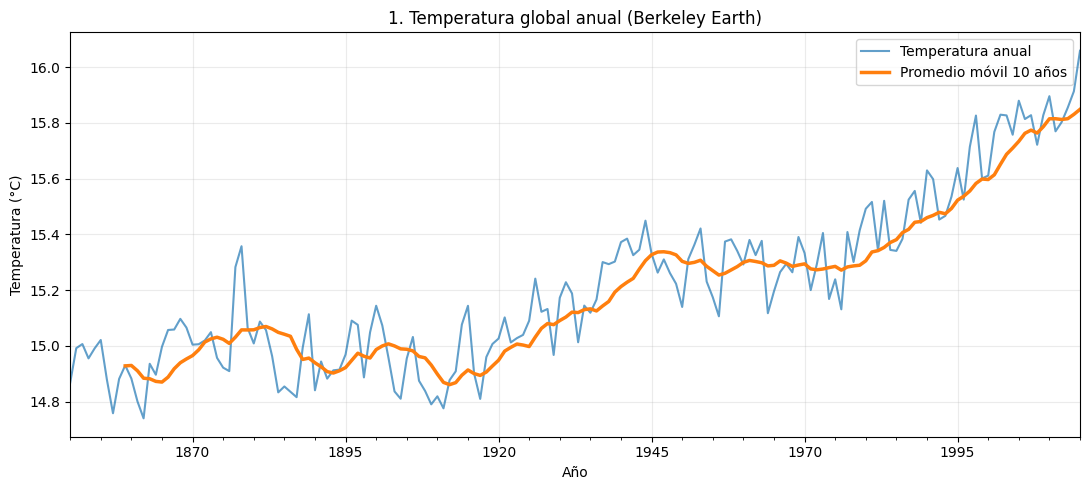

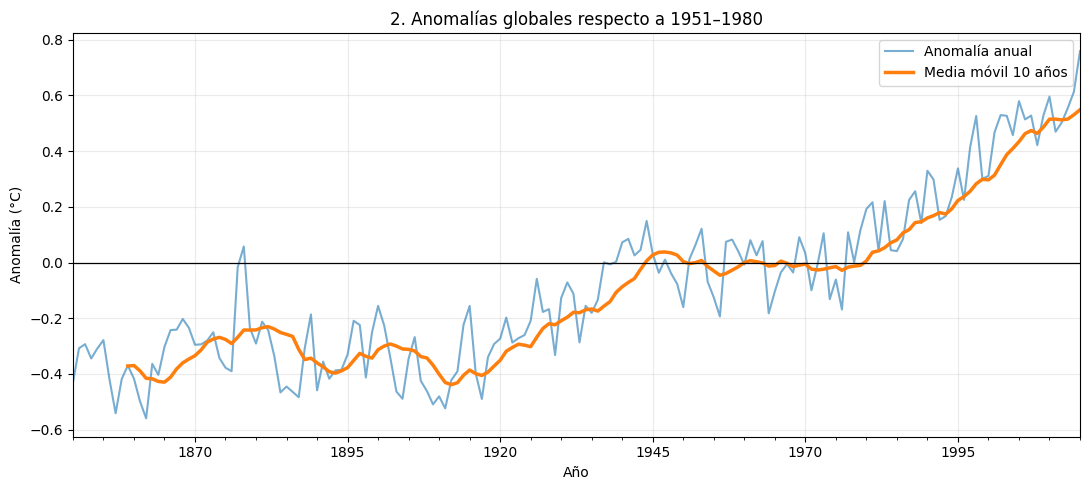

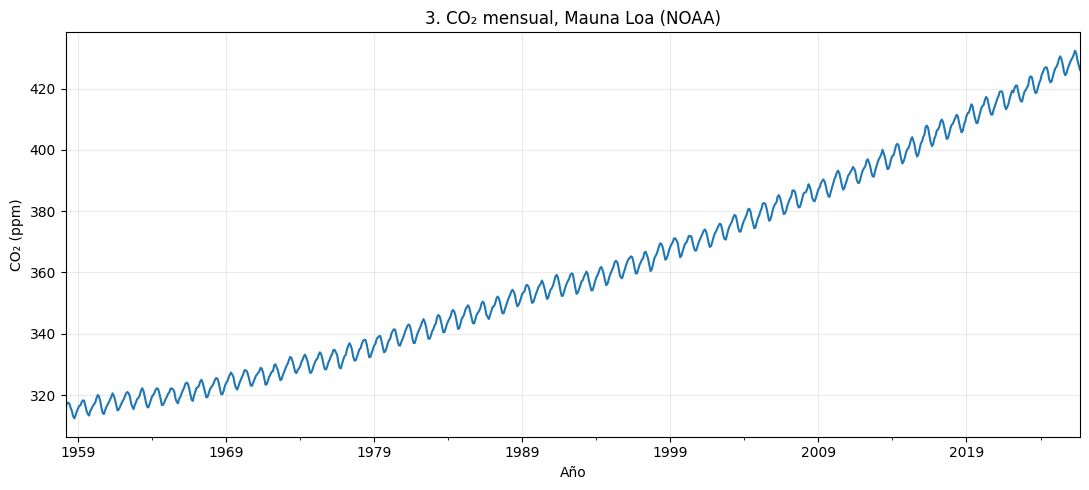

In [9]:
def save(name):
    plt.tight_layout(); plt.savefig(FIG/name,dpi=160,bbox_inches='tight'); plt.show()

# Figura 1: temperatura global anual
ax=annual['mean'].plot(label='Temperatura anual',alpha=.7)
annual['mean'].rolling(10,min_periods=10).mean().plot(ax=ax,label='Promedio móvil 10 años',lw=2.5)
ax.set(title='1. Temperatura global anual (Berkeley Earth)',xlabel='Año',ylabel='Temperatura (°C)'); ax.legend()
save('01_global_temperature.png')

# Figura 2: anomalías
ax=annual['anomaly'].plot(label='Anomalía anual',alpha=.6)
annual['rolling_10y'].plot(ax=ax,label='Media móvil 10 años',lw=2.5)
ax.axhline(0,color='black',lw=.9)
ax.set(title='2. Anomalías globales respecto a 1951–1980',xlabel='Año',ylabel='Anomalía (°C)'); ax.legend()
save('02_global_anomalies.png')

# Figura 3: CO2
ax=co2.set_index('dt')['average'].plot()
ax.set(title='3. CO₂ mensual, Mauna Loa (NOAA)',xlabel='Año',ylabel='CO₂ (ppm)')
save('03_co2.png')

In [10]:
first,last=annual.dropna(subset=['mean']).iloc[[0,-1]].iterrows()
display(Markdown(f"**Figure 1.** The available complete annual record spans {first[0].year}–{last[0].year}; the 10-year mean highlights changes beyond year-to-year variability. Its endpoints differ by {last[1]['mean']-first[1]['mean']:.2f}°C; the formal slope analysis follows in Section 6."))
display(Markdown(f"**Figure 2.** Anomalies use a {baseline:.3f}°C reference mean across 30 complete years in 1951–1980. The last complete year has an anomaly of {last[1]['anomaly']:+.3f}°C; positive values mean warmer than that reference."))
valid_co2=co2.dropna(subset=['average']).sort_values('dt')
display(Markdown(f"**Figure 3.** Monthly Mauna Loa CO₂ rises from {valid_co2.average.iloc[0]:.2f} to {valid_co2.average.iloc[-1]:.2f} ppm over {valid_co2.dt.iloc[0]:%Y-%m}–{valid_co2.dt.iloc[-1]:%Y-%m}. Seasonal variation sits on a longer-term increase; association with temperature is assessed separately."))

**Figure 1.** The available complete annual record spans 1850–2015; the 10-year mean highlights changes beyond year-to-year variability. Its endpoints differ by 1.19°C; the formal slope analysis follows in Section 6.

**Figure 2.** Anomalies use a 15.300°C reference mean across 30 complete years in 1951–1980. The last complete year has an anomaly of +0.759°C; positive values mean warmer than that reference.

**Figure 3.** Monthly Mauna Loa CO₂ rises from 315.71 to 426.07 ppm over 1958-03–2026-09. Seasonal variation sits on a longer-term increase; association with temperature is assessed separately.

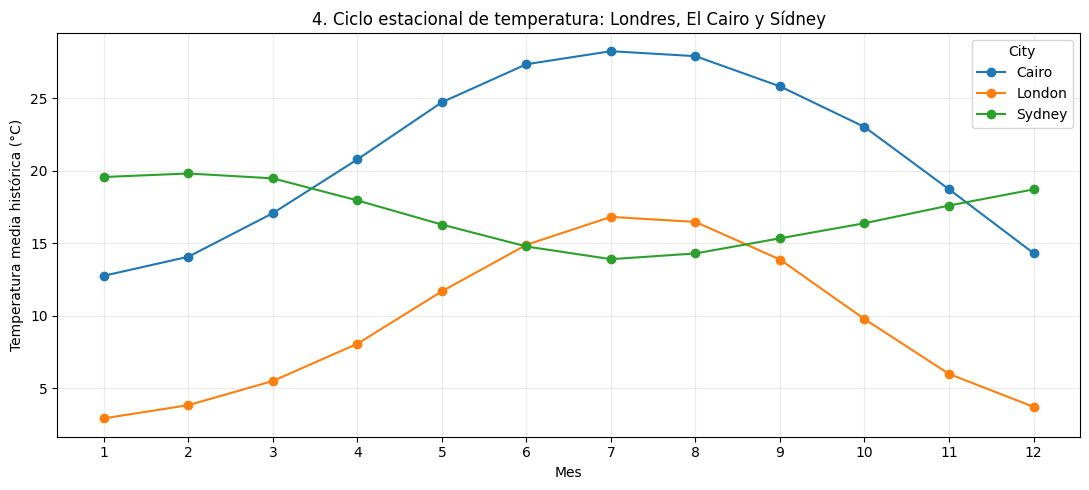

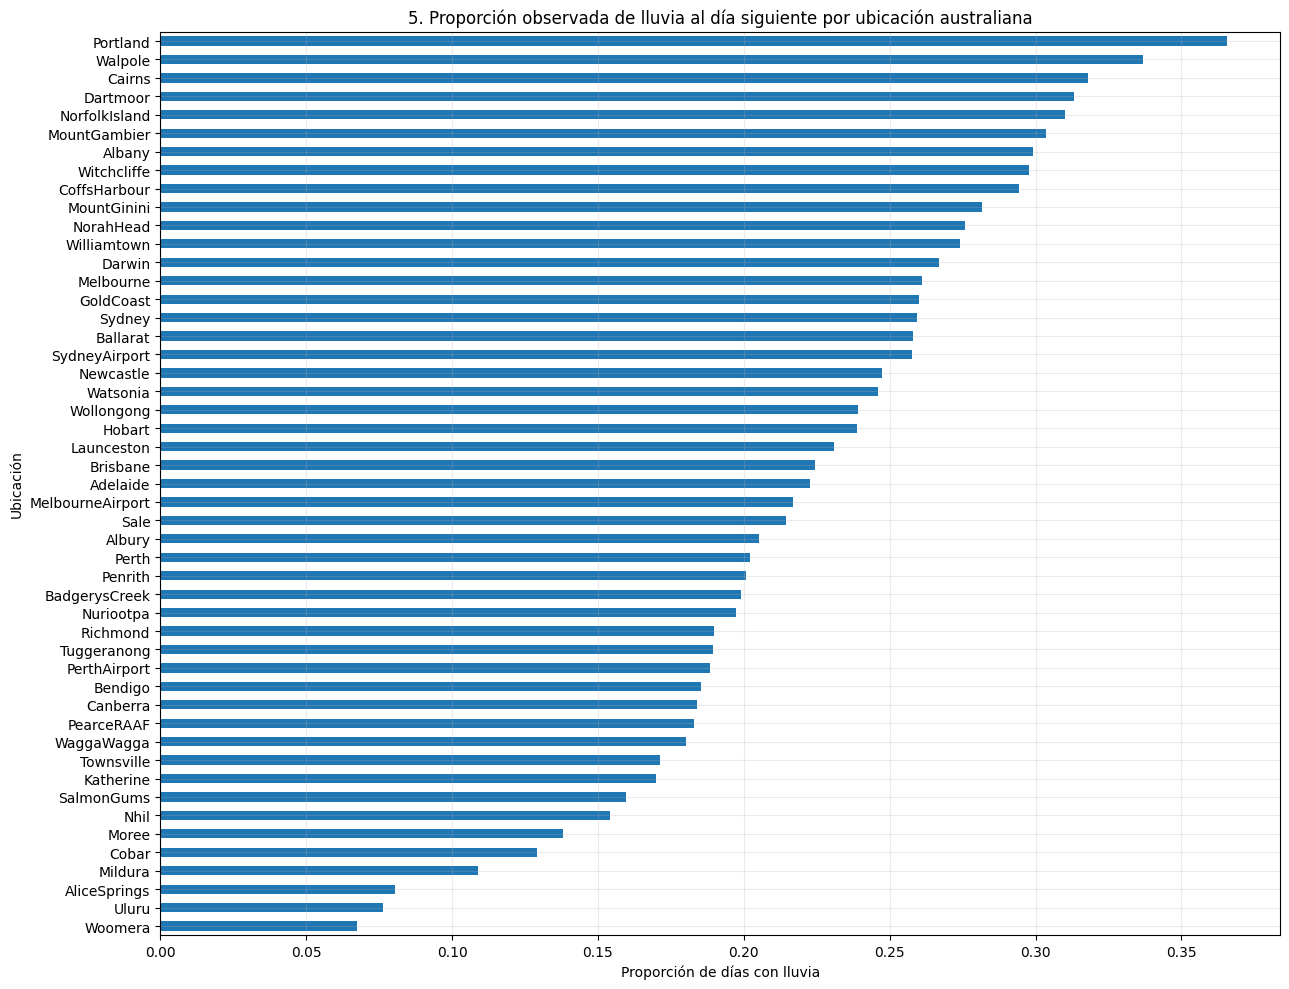

In [11]:
# Figura 4: ciclos mensuales de 3 ciudades con climas contrastantes
subset=selected[selected['City'].isin(['London','Cairo','Sydney'])].dropna(subset=['AverageTemperature']).copy()
subset['month']=subset.dt.dt.month
cycles=subset.groupby(['City','month'])['AverageTemperature'].mean().unstack(0)
ax=cycles.plot(marker='o')
ax.set(title='4. Ciclo estacional de temperatura: Londres, El Cairo y Sídney',xlabel='Mes',ylabel='Temperatura media histórica (°C)')
ax.set_xticks(range(1,13));save('04_monthly_cycles.png')

# Figura 5: frecuencia de lluvia por ubicación australiana
rain_valid=rain.dropna(subset=['RainTomorrow'])
frequency=rain_valid.assign(rain_yes=rain_valid['RainTomorrow'].eq('Yes')).groupby('Location')['rain_yes'].mean().sort_values()
fig,ax=plt.subplots(figsize=(13,10))
frequency.plot.barh(ax=ax)
ax.set(title='5. Proporción observada de lluvia al día siguiente por ubicación australiana',xlabel='Proporción de días con lluvia',ylabel='Ubicación')
save('05_rain_frequency.png')

In [12]:
ranges=cycles.max()-cycles.min()
display(Markdown("**Figure 4.** The observed seasonal temperature ranges are "+", ".join(f"{city}: {value:.1f}°C" for city,value in ranges.items())+". Sydney's seasonal timing differs from the Northern Hemisphere cities; these historical cycles are descriptive rather than forecasts."))
display(Markdown(f"**Figure 5.** Next-day rain frequencies range from {frequency.min():.1%} at {frequency.idxmin()} to {frequency.max():.1%} at {frequency.idxmax()}. Location differences mean a single overall accuracy can hide weak performance at wetter locations."))

**Figure 4.** The observed seasonal temperature ranges are Cairo: 15.5°C, London: 13.9°C, Sydney: 5.9°C. Sydney's seasonal timing differs from the Northern Hemisphere cities; these historical cycles are descriptive rather than forecasts.

**Figure 5.** Next-day rain frequencies range from 6.8% at Woomera to 36.5% at Portland. Location differences mean a single overall accuracy can hide weak performance at wetter locations.

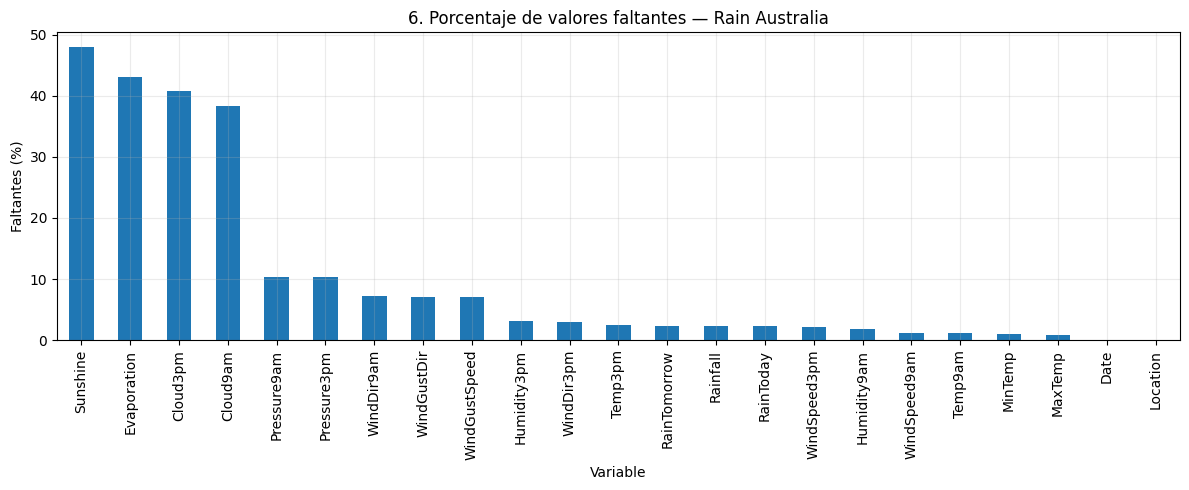

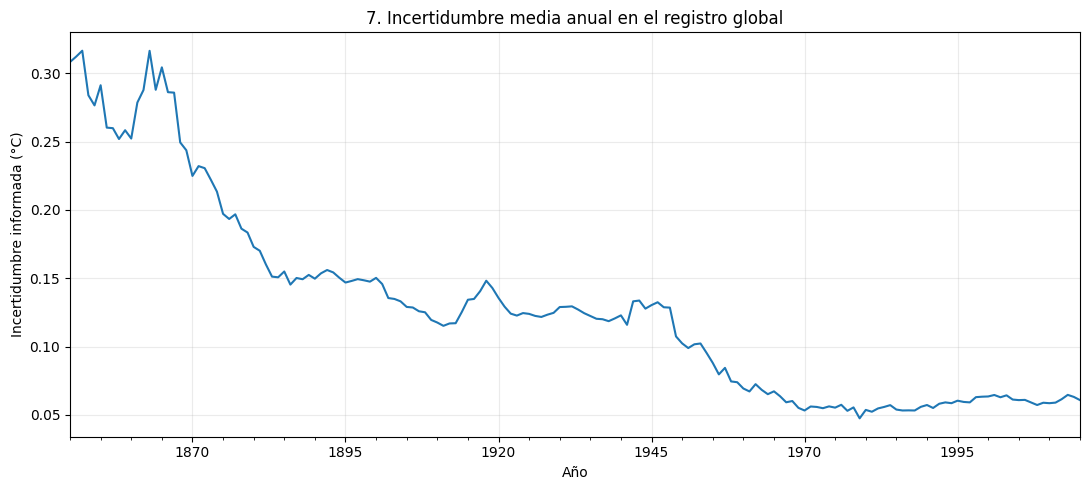

In [13]:
# Figura 6: faltantes por variable en datos de Australia
frac=rain.isna().mean().sort_values(ascending=False)
ax=(100*frac).plot.bar(figsize=(12,5))
ax.set(title='6. Porcentaje de valores faltantes — Rain Australia',xlabel='Variable',ylabel='Faltantes (%)')
save('06_missingness.png')

# Figura 7: incertidumbre reportada en temperatura global
unc='LandAndOceanAverageTemperatureUncertainty'
if unc not in glob.columns: raise KeyError(f'Columna de incertidumbre no encontrada: {unc}')
uncertainty=glob.set_index('dt')[unc].resample('YS').mean().loc['1850':]
ax=uncertainty.plot()
ax.set(title='7. Incertidumbre media anual en el registro global',xlabel='Año',ylabel='Incertidumbre informada (°C)')
save('07_source_uncertainty.png')

In [14]:
display(Markdown("**Figure 6.** The largest missing fractions are "+", ".join(f"{key}: {value:.1%}" for key,value in frac.head(3).items())+". These variables require training-fold imputation; a missing measurement must not be interpreted as zero."))
display(Markdown(f"**Figure 7.** Mean reported uncertainty is {uncertainty.loc['1850':'1899'].mean():.3f}°C in 1850–1899 and {uncertainty.loc['1950':].mean():.3f}°C from 1950 onward. This is uncertainty in the source temperature product, distinct from model prediction error."))

**Figure 6.** The largest missing fractions are Sunshine: 48.0%, Evaporation: 43.2%, Cloud3pm: 40.8%. These variables require training-fold imputation; a missing measurement must not be interpreted as zero.

**Figure 7.** Mean reported uncertainty is 0.215°C in 1850–1899 and 0.064°C from 1950 onward. This is uncertainty in the source temperature product, distinct from model prediction error.

### 3.3. Data-quality interpretation
The seven figure interpretations are computed from the loaded data below. Berkeley, NOAA, Australia and Puerto Rico cover different periods and variables. Do not merge their rows as interchangeable weather observations. Missing daily temperatures remain missing rather than becoming non-heat days; source uncertainty is not model prediction uncertainty.


In [15]:
assert len(CITIES)==10 and len(city_cov)==10
assert int(base.notna().sum())==30
assert len(list(FIG.glob('0[1-7]_*.png')))>=7
assert (OUT/'data_coverage.csv').exists()
print('FASE 1: verificaciones básicas aprobadas')
print('Figuras generadas:')
for file in sorted(FIG.glob('0[1-7]_*.png')): print(' -',file)
print('Archivos de auditoría:', list(OUT.glob('*.csv')))

FASE 1: verificaciones básicas aprobadas
Figuras generadas:
 - /workspace/scratch/1136345488e7/final_run/figures/01_global_temperature.png
 - /workspace/scratch/1136345488e7/final_run/figures/02_global_anomalies.png
 - /workspace/scratch/1136345488e7/final_run/figures/03_co2.png
 - /workspace/scratch/1136345488e7/final_run/figures/04_monthly_cycles.png
 - /workspace/scratch/1136345488e7/final_run/figures/05_rain_frequency.png
 - /workspace/scratch/1136345488e7/final_run/figures/06_missingness.png
 - /workspace/scratch/1136345488e7/final_run/figures/07_source_uncertainty.png
Archivos de auditoría: [PosixPath('/workspace/scratch/1136345488e7/final_run/outputs/phase1/rain_class_balance.csv'), PosixPath('/workspace/scratch/1136345488e7/final_run/outputs/phase1/data_coverage.csv'), PosixPath('/workspace/scratch/1136345488e7/final_run/outputs/phase1/global_annual_anomalies_1951_1980.csv'), PosixPath('/workspace/scratch/1136345488e7/final_run/outputs/phase1/city_coverage.csv')]


## 4. Preprocessing and train / validation / test split
Time order is preserved in every experiment. Model-specific transformations are fit **inside** training pipelines; never on validation or test partitions. Feature windows for time-series prediction are constructed from observations available at the forecast origin.

**Dates:** city models train through December 2000 and test from January 2001 through available 2013 observations; twelve-month forecasts purge eleven months at the initial origin and each CV boundary. Australian rain trains through 2015 and tests from 2016; CV groups all locations on the same calendar date together and leaves a one-date gap. Heat uses the final five calendar years as test and the same calendar-based CV within training. Scaling, imputation and encoding are fit inside the training pipeline. No hyperparameter/model selection uses test scores.

**Targets and scope:** full-record tmax 90th percentile is the assignment's retrospective heat definition. It deliberately uses the record to define labels; this is not an operational threshold estimated only from past data. Feature lags are calendar-based. A twelve-month horizon is tested for Ridge and seasonal naive; the full ten-model comparison is the required monthly lagged experiment. Rain uses a shared, uniformly time-spaced sample of at most 24,000 training rows; the test set is complete. Balanced class weights address imbalance for supported classifiers; F1 tuning and precision/recall expose the behavior of other families, without resampling test data.


In [16]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, RocCurveDisplay
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.svm import SVR, SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, GradientBoostingRegressor, GradientBoostingClassifier
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
import time, warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from IPython.display import Markdown
FIT_WARNINGS=[]
MODEL_RESULTS=[]
REGRESSION_ROWS=[]
CLASSIFICATION_ROWS=[]
SEED=42

def save_fig(name):
    plt.tight_layout();plt.savefig(FIG/name,dpi=150,bbox_inches='tight');plt.show()

# Split on unique calendar dates so observations from the same date never
# appear in both sides of a rainfall cross-validation fold.
def calendar_cv(frame, n_splits=3):
    dates = pd.to_datetime(frame['Date']).reset_index(drop=True)
    unique_dates = np.sort(dates.unique())
    folds = []
    for tr, va in TimeSeriesSplit(n_splits=n_splits,gap=1).split(unique_dates):
        train_ids = np.flatnonzero(dates.isin(unique_dates[tr]).to_numpy())
        valid_ids = np.flatnonzero(dates.isin(unique_dates[va]).to_numpy())
        assert dates.iloc[train_ids].max() < dates.iloc[valid_ids].min()
        folds.append((train_ids, valid_ids))
    return folds

versions = {pkg: importlib.metadata.version(pkg) for pkg in
            ['pandas','numpy','matplotlib','seaborn','scikit-learn','scipy','kagglehub','meteostat','rasterio']}
(RUN_DIR / 'tested_versions.json').write_text(json.dumps(versions, indent=2))
print('Python:', sys.version.split()[0], '| Model-search workers:', N_JOBS)
print(versions)


Python: 3.12.14 | Model-search workers: 2
{'pandas': '3.1.0', 'numpy': '2.3.5', 'matplotlib': '3.10.8', 'seaborn': '0.13.2', 'scikit-learn': '1.8.0', 'scipy': '1.17.0', 'kagglehub': '1.0.3', 'meteostat': '2.1.5', 'rasterio': '1.5.2'}


## 5. Unsupervised analysis: PCA and K-Means
Use 1961–1990 normals for the ten selected cities; for the required **20-city Köppen comparison**, add ten further well-documented cities from the Berkeley source. Do not equate K-Means cluster IDs to Köppen climate classes.

K selected: 3 Cities: 20
Köppen adjusted Rand index: 0.0596


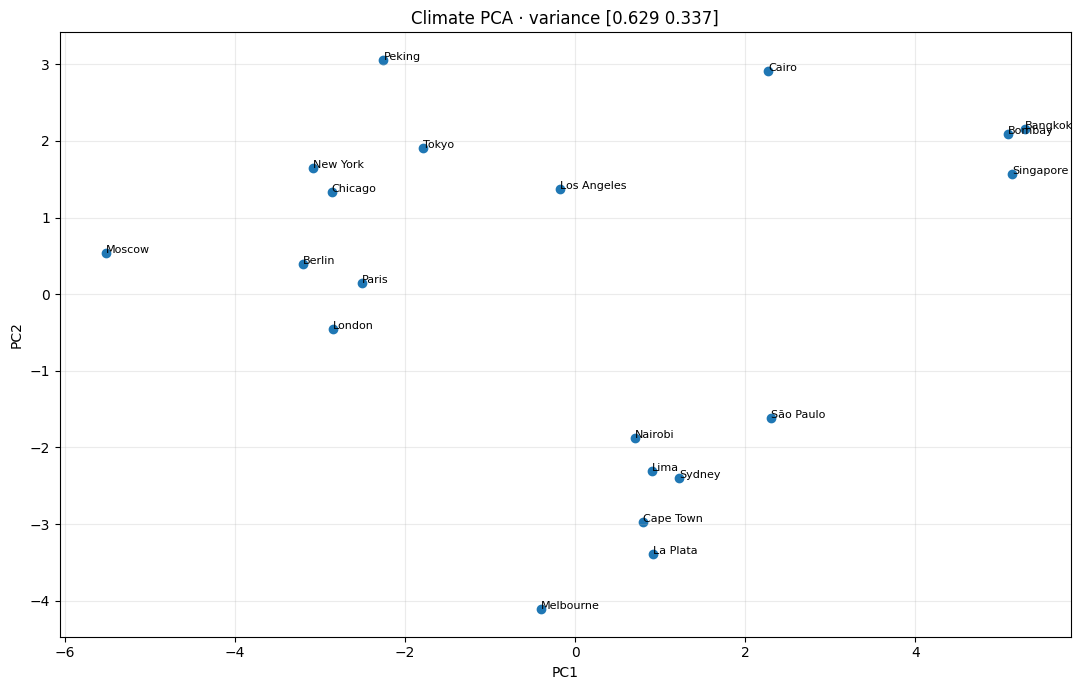

,PC1,PC2
month,,
1,0.305064,-0.192736
2,0.309935,-0.177830
3,0.324445,-0.118962
4,0.331834,0.029772
5,0.275599,0.244207
6,0.163946,0.397952
7,0.090817,0.442595
8,0.107643,0.432105
9,0.225849,0.334070


,k,inertia,silhouette
0,2,141.236370,0.451837
1,3,49.730832,0.607599
2,4,35.759086,0.505972
3,5,28.526323,0.480206
4,6,21.249686,0.499314
5,7,16.271120,0.365008
6,8,11.018455,0.364984
7,9,8.151674,0.354800
8,10,6.126871,0.328365


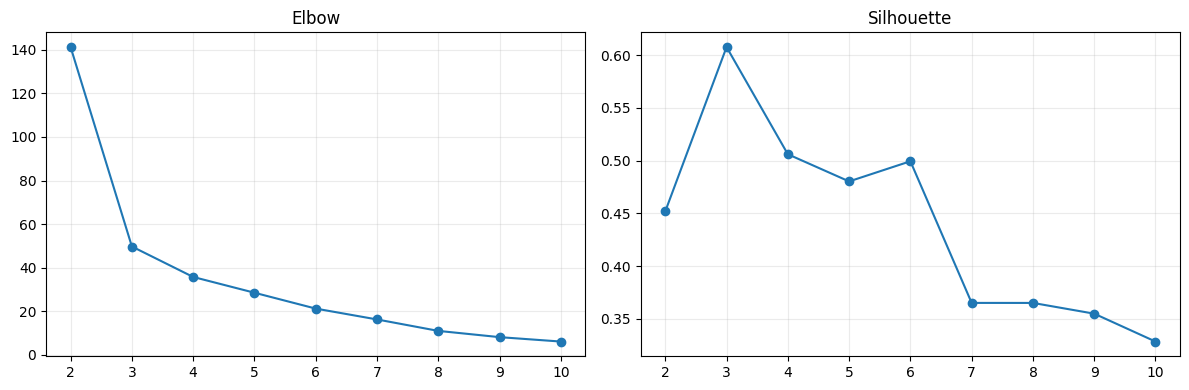

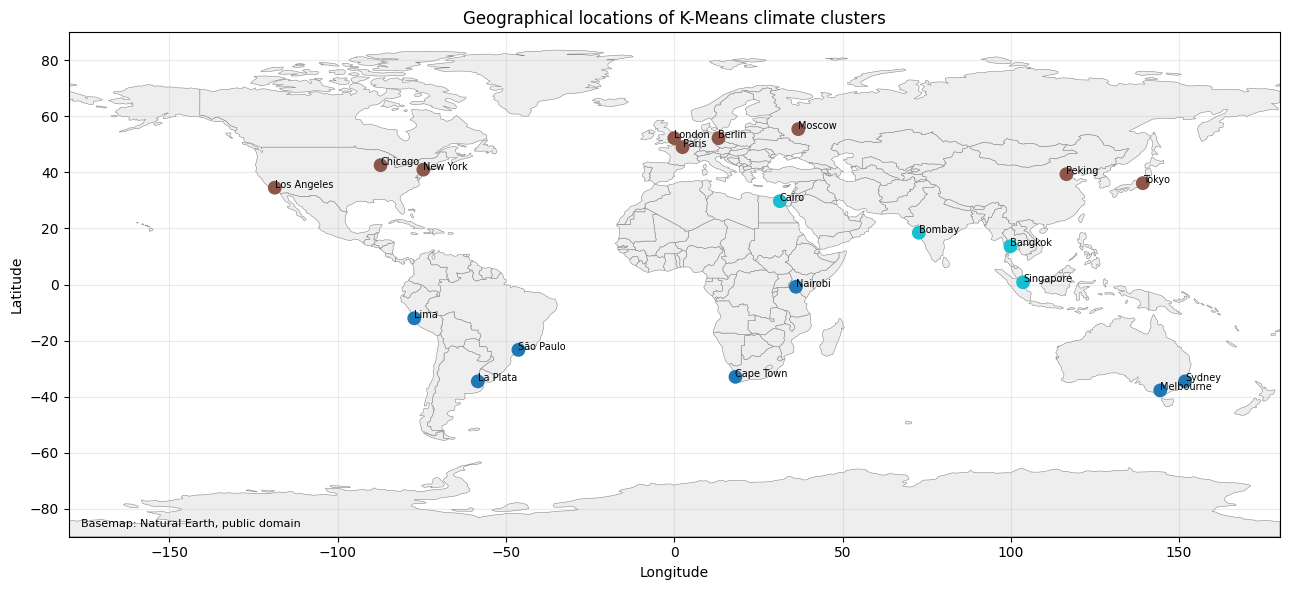

,City,Country,cluster,Koppen
0,Bangkok,Thailand,2,Aw
1,Berlin,Germany,1,Dfb
2,Bombay,India,2,Am
3,Cairo,Egypt,2,BWh
4,Cape Town,South Africa,0,Csb
5,Chicago,United States,1,Dfa
6,La Plata,Argentina,0,Cfa
7,Lima,Peru,0,BWh
8,London,United Kingdom,1,Cfb
9,Los Angeles,United States,1,Csa


Koppen,Af,Am,Aw,BWh,Cfa,Cfb,Csa,Csb,Dfa,Dfb,Dwa
cluster,,,,,,,,,,,
0,0,0,0,1,3,2,0,1,0,0,0
1,0,0,0,0,1,2,1,0,2,2,1
2,1,1,1,1,0,0,0,0,0,0,0


In [17]:
# Additional well-known cities are selected only for the Phase 4 reference comparison.
EXTRA_CITIES=[('Los Angeles','United States'),('Chicago','United States'),('Berlin','Germany'),
 ('Moscow','Russia'),('Peking','China'),('Bangkok','Thailand'),('Singapore','Singapore'),
 ('Melbourne','Australia'),('Lima','Peru'),('Nairobi','Kenya')]
all_pairs=CITIES+EXTRA_CITIES
parts=[selected]
for chunk in pd.read_csv(paths['cities'],parse_dates=['dt'],chunksize=250_000):
    mask=pd.MultiIndex.from_frame(chunk[['City','Country']]).isin(EXTRA_CITIES)
    sub=chunk.loc[mask]
    if not sub.empty:parts.append(sub)
climate_cities=pd.concat(parts,ignore_index=True)
climate_cities['month']=climate_cities.dt.dt.month
normals=climate_cities[climate_cities.dt.dt.year.between(1961,1990)]
clim=normals.groupby(['City','Country','month'])['AverageTemperature'].agg(['mean','count']).reset_index()
clim.loc[clim['count']<20,'mean']=np.nan
wide=clim.pivot(index=['City','Country'],columns='month',values='mean').reindex(columns=range(1,13)).dropna()
geo=normals.groupby(['City','Country'])[['Latitude','Longitude']].first().reindex(wide.index)
def parse_degree(s):
    if isinstance(s,(int,float)):return float(s)
    v=str(s).strip();return float(v[:-1])*(-1 if v[-1] in 'SW' else 1)
geo=geo.map(parse_degree)
profile=wide.copy();profile['annual_range']=wide.max(axis=1)-wide.min(axis=1);profile['latitude']=geo.Latitude
profile.columns=profile.columns.astype(str)
assert len(profile)==20, f'Expected 20 complete reference cities; got {len(profile)}'
if len(profile)<10:raise RuntimeError(f'Not enough complete reference cities: {len(profile)}')
X=StandardScaler().fit_transform(profile)
coords=PCA(n_components=2).fit_transform(X)
components=PCA(n_components=2).fit(X)
fig,ax=plt.subplots(figsize=(11,7));ax.scatter(coords[:,0],coords[:,1])
for i,(city,country) in enumerate(profile.index):ax.annotate(city,coords[i],fontsize=8)
ax.set(xlabel='PC1',ylabel='PC2',title=f'Climate PCA · variance {components.explained_variance_ratio_.round(3)}')
save_fig('phase4_pca.png')
display(pd.DataFrame(components.components_.T,index=profile.columns,columns=['PC1','PC2']))
ks=range(2,min(10,len(profile)-1)+1);diag=[]
for k in ks:
    km=KMeans(n_clusters=k,n_init=20,random_state=SEED).fit(X)
    diag.append({'k':k,'inertia':km.inertia_,'silhouette':silhouette_score(X,km.labels_)})
clust_diag=pd.DataFrame(diag);display(clust_diag)
fig,axs=plt.subplots(1,2,figsize=(12,4));axs[0].plot(clust_diag.k,clust_diag.inertia,'o-');axs[0].set_title('Elbow');axs[1].plot(clust_diag.k,clust_diag.silhouette,'o-');axs[1].set_title('Silhouette');save_fig('phase4_cluster_diagnostics.png')
best_k=int(clust_diag.loc[clust_diag.silhouette.idxmax(),'k'])
labels=KMeans(n_clusters=best_k,n_init=20,random_state=SEED).fit_predict(X)
clusters=geo.copy();clusters['cluster']=labels;clusters['city']=[i[0] for i in clusters.index]
fig,ax=plt.subplots(figsize=(13,6))
world_path=RAW/'ne_110m_admin_0_countries.geojson'
if not world_path.exists():
    urllib.request.urlretrieve('https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson',world_path)
world=json.loads(world_path.read_text())
for feature in world['features']:
    geom=feature['geometry']
    polygons=geom['coordinates'] if geom['type']=='MultiPolygon' else [geom['coordinates']]
    for polygon in polygons:
        xy=np.array(polygon[0]);ax.fill(xy[:,0],xy[:,1],facecolor='#eeeeee',edgecolor='#888888',linewidth=.4,zorder=0)
ax.scatter(clusters.Longitude,clusters.Latitude,c=labels,cmap='tab10',s=80,zorder=2)
ax.text(.01,.02,'Basemap: Natural Earth, public domain',transform=ax.transAxes,fontsize=8)
for r in clusters.itertuples():ax.annotate(r.city,(r.Longitude,r.Latitude),fontsize=7)
ax.set(xlim=(-180,180),ylim=(-90,90),xlabel='Longitude',ylabel='Latitude',title='Geographical locations of K-Means climate clusters')
save_fig('phase4_geo_clusters.png')
print('K selected:',best_k,'Cities:',len(profile))
# Beck et al. (2023), Scientific Data, DOI 10.1038/s41597-023-02549-6.
# Figshare article 21789074, version 2: published historical 1961-1990 raster.
# City centre coordinates are independently resolved through the GeoNames gazetteer.
import zipfile, re, requests, rasterio
archive = RAW / 'koppen_geiger_tif.zip'
if not archive.exists():
    print('Downloading published Köppen-Geiger reference (~131 MB)...', flush=True)
    with requests.get('https://ndownloader.figshare.com/files/61012822', stream=True, timeout=120) as response:
        response.raise_for_status()
        partial = archive.with_suffix('.part')
        with partial.open('wb') as target:
            for block in response.iter_content(1024 * 1024): target.write(block)
        partial.replace(archive)
with zipfile.ZipFile(archive) as z:
    candidates = [s for s in z.namelist() if '1961_1990' in s and s.endswith('koppen_geiger_0p1.tif')]
    assert len(candidates)==1, f'Could not uniquely resolve historical raster: {candidates}'
    raster_name = candidates[0]
    legend_names = [s for s in z.namelist() if s.lower().endswith('legend.txt')]
    assert legend_names, 'Missing Köppen class legend'
    legend_text = z.read(legend_names[0]).decode('utf-8-sig')
    legend = {}
    for line in legend_text.splitlines():
        match = re.match(r'\s*(\d+)\s*:?\s+([A-E][A-Za-z]{1,2})\b', line)
        if match: legend[int(match.group(1))] = match.group(2)
    assert len(legend)==30, f'Expected 30 published climate symbols; parsed {len(legend)}'
    raster_path = RAW / 'koppen_1961_1990_0p1.tif'
    if not raster_path.exists(): raster_path.write_bytes(z.read(raster_name))
# GeoNames city centres avoid sampling ocean cells at Berkeley's coarse grid centres.
# The published Köppen class is sampled independently at the documented city point.
import io, unicodedata
geonames_zip = RAW/'cities15000.zip'
if not geonames_zip.exists():
    with requests.get('https://download.geonames.org/export/dump/cities15000.zip',timeout=120) as response:
        response.raise_for_status(); geonames_zip.write_bytes(response.content)
with zipfile.ZipFile(geonames_zip) as z:
    places = pd.read_csv(io.BytesIO(z.read('cities15000.txt')),sep='\t',header=None,
        usecols=[0,1,2,4,5,8,14],names=['geonameid','name','ascii','lat','lon','iso','population'])
def normalized_name(value):
    return unicodedata.normalize('NFKD',str(value)).encode('ascii','ignore').decode().casefold()
places['key']=places['ascii'].map(normalized_name)
iso_codes={'United States':'US','United Kingdom':'GB','France':'FR','Egypt':'EG','India':'IN',
    'Japan':'JP','Australia':'AU','South Africa':'ZA','Brazil':'BR','Argentina':'AR',
    'Germany':'DE','Russia':'RU','China':'CN','Thailand':'TH','Singapore':'SG','Peru':'PE','Kenya':'KE'}
aliases={'Bombay':'Mumbai','Peking':'Beijing','New York':'New York City'}
reference=geo.reset_index().copy()
city_points=[]
for city,country in reference[['City','Country']].itertuples(index=False,name=None):
    name=normalized_name(aliases.get(city,city))
    candidates=places[(places['key']==name)&(places['iso']==iso_codes[country])].sort_values('population',ascending=False)
    assert not candidates.empty, f'GeoNames city centre unavailable: {city}, {country}'
    city_points.append(candidates.iloc[0])
reference['city_latitude']=[point['lat'] for point in city_points]
reference['city_longitude']=[point['lon'] for point in city_points]
reference['geonameid']=[int(point['geonameid']) for point in city_points]
with rasterio.open(raster_path) as dataset:
    codes=[int(value[0]) for value in dataset.sample(zip(reference.city_longitude,reference.city_latitude))]
reference['Koppen']=[legend.get(code) for code in codes]
reference['source']='Beck et al. (2023); Figshare 21789074 v2; 1961-1990; 0.1 degree; GeoNames city centre'
assert reference.Koppen.notna().all(), 'A GeoNames city point has no land classification; inspect coordinates.'
reference.to_csv(RAW/'koppen_reference.csv',index=False)
check = clusters.reset_index().merge(reference[['City','Country','Koppen']],on=['City','Country'],validate='one_to_one')
assert len(check)==20
koppen_ari = adjusted_rand_score(check.Koppen,check.cluster)
display(check[['City','Country','cluster','Koppen']])
display(pd.crosstab(check.cluster,check.Koppen))
print('Köppen adjusted Rand index:', round(koppen_ari,4))
check.to_csv(OUT/'phase4_clusters_koppen.csv',index=False)
clust_diag.to_csv(OUT/'phase4_cluster_diagnostics.csv',index=False)


## 6. Supervised models
Each model is trained only on the training period, with hyperparameters selected through cross-validation. The test interval is untouched during tuning.

### 6.1. Global trend regression


In [18]:
from scipy.stats import linregress, t
trend=annual.dropna(subset=['anomaly']).copy()
trend['year']=trend.index.year
for label,frame in [('1850–1974',trend[trend.year<=1974]),('1975–latest',trend[trend.year>=1975]),('All',trend)]:
    lr=linregress(frame.year,frame.anomaly)
    critical=t.ppf(.975,len(frame)-2)
    lo,hi=(lr.slope-critical*lr.stderr)*10,(lr.slope+critical*lr.stderr)*10
    print(label,'warming °C/decade:',round(lr.slope*10,4),'95% CI:',(round(lo,4),round(hi,4)))
    MODEL_RESULTS.append({'task':'global trend','model':label,'test_metric':'warming_C_per_decade','value':lr.slope*10,'ci_low':lo,'ci_high':hi,'first_year':int(frame.year.min()),'last_year':int(frame.year.max())})

# Descriptive slopes above use the full record; predictive scores below are held out.
co2annual=co2.assign(year=co2.dt.dt.year).groupby('year')['average'].mean().rename('co2')
trend_frame=trend[['anomaly','year']].copy()
phase2_rows=[]
def evaluate_trend(frame,columns,estimator,grid,model_name,co2_flag=False):
    train=frame[frame.year<=2000];test=frame[frame.year>2000]
    search=GridSearchCV(estimator,grid,cv=TimeSeriesSplit(n_splits=4),scoring='neg_mean_absolute_error',n_jobs=N_JOBS)
    tic=time.perf_counter();search.fit(train[columns],train.anomaly);train_s=time.perf_counter()-tic
    tic=time.perf_counter();pred=search.predict(test[columns]);pred_s=time.perf_counter()-tic
    phase2_rows.append(dict(task='global temperature',model=model_name,with_co2=co2_flag,
        train_start=int(train.year.min()),train_end=2000,test_start=int(test.year.min()),test_end=int(test.year.max()),
        params=str(search.best_params_),cv_mean=-search.best_score_,
        cv_sd=search.cv_results_['std_test_score'][search.best_index_],
        MAE=mean_absolute_error(test.anomaly,pred),RMSE=np.sqrt(mean_squared_error(test.anomaly,pred)),
        R2=r2_score(test.anomaly,pred),train_seconds=train_s,predict_seconds=pred_s))
for degree in [1,2,3]:
    pipeline=Pipeline([('scale',StandardScaler()),('poly',PolynomialFeatures(degree=degree,include_bias=False)),('model',LinearRegression())])
    evaluate_trend(trend_frame,['year'],pipeline,{},'Linear trend' if degree==1 else f'Polynomial trend degree {degree}')
joined=trend_frame.set_index('year')[['anomaly']].join(co2annual).dropna().loc[1958:].reset_index()
for with_co2 in [False,True]:
    for name,reg in [('Ridge',Ridge()),('Lasso',Lasso(max_iter=20000))]:
        evaluate_trend(joined,['year']+(['co2'] if with_co2 else []),
            Pipeline([('scale',StandardScaler()),('reg',reg)]),{'reg__alpha':[.001,.01,.1,1,10,100]},name,with_co2)
phase2_table=pd.DataFrame(phase2_rows)
display(phase2_table)
phase2_table.to_csv(OUT/'phase2_trend_models.csv',index=False)
pd.DataFrame(MODEL_RESULTS).to_csv(OUT/'phase2_warming_slopes.csv',index=False)
# Observed test-year CO2 makes these conditional estimates, not forecasts of future CO2.


1850–1974 warming °C/decade: 0.036 95% CI: (np.float64(0.0296), np.float64(0.0424))
1975–latest warming °C/decade: 0.1642 95% CI: (np.float64(0.1405), np.float64(0.1878))
All warming °C/decade: 0.0535 95% CI: (np.float64(0.0486), np.float64(0.0584))


,task,model,with_co2,train_start,train_end,test_start,test_end,params,cv_mean,cv_sd,MAE,RMSE,R2,train_seconds,predict_seconds
0,global temperature,Linear trend,False,1850,2000,2001,2015,{},0.182032,0.042206,0.320942,0.328474,-16.661862,0.025792,0.001127
1,global temperature,Polynomial trend degree 2,False,1850,2000,2001,2015,{},0.324505,0.227196,0.146633,0.160774,-3.231252,0.032444,0.001193
2,global temperature,Polynomial trend degree 3,False,1850,2000,2001,2015,{},0.478969,0.222177,0.171223,0.183569,-4.516107,0.023086,0.000979
3,global temperature,Ridge,False,1958,2000,2001,2015,{'reg__alpha': 1},0.130218,0.049408,0.160899,0.173988,-3.955361,0.100026,0.001144
4,global temperature,Lasso,False,1958,2000,2001,2015,{'reg__alpha': 0.01},0.131209,0.039433,0.178066,0.190019,-4.910569,0.120582,0.001074
5,global temperature,Ridge,True,1958,2000,2001,2015,{'reg__alpha': 0.1},0.093231,0.026557,0.100941,0.118874,-1.313188,0.114064,0.001687
6,global temperature,Lasso,True,1958,2000,2001,2015,{'reg__alpha': 0.001},0.102480,0.038475,0.091619,0.109321,-0.956351,0.101550,0.001077


### 6.2. One-month city forecasting
The lagged ten-model comparison forecasts one month ahead. The additional 12-month-horizon experiment uses only information observed at least 12 months before the target, avoiding test-period target leakage.

#### 6.2.1. Linear regression
Unpenalized reference; no tunable regularization parameter. Three expanding-window folds use MAE. The shared loop below fits this family independently for each city and saves hyperparameters, CV variation, held-out metrics and timings.

#### 6.2.2. Ridge regression
Tune alpha in 0.1, 1 and 10. Three expanding-window folds use MAE. The shared loop below fits this family independently for each city and saves hyperparameters, CV variation, held-out metrics and timings.

#### 6.2.3. Lasso regression
Tune alpha in 0.001, 0.01 and 0.1. Three expanding-window folds use MAE. The shared loop below fits this family independently for each city and saves hyperparameters, CV variation, held-out metrics and timings.

#### 6.2.4. Polynomial regression
Degree 2 expansion with Ridge alpha 1 or 10; global trends also evaluate degrees 2 and 3. Three expanding-window folds use MAE. The shared loop below fits this family independently for each city and saves hyperparameters, CV variation, held-out metrics and timings.

#### 6.2.5. k-Nearest Neighbors regression
Tune 3 or 7 neighbors after scaling. Three expanding-window folds use MAE. The shared loop below fits this family independently for each city and saves hyperparameters, CV variation, held-out metrics and timings.

#### 6.2.6. Decision tree regression
Tune maximum depth 4 or 8. Three expanding-window folds use MAE. The shared loop below fits this family independently for each city and saves hyperparameters, CV variation, held-out metrics and timings.

#### 6.2.7. Random forest regression
80 trees; tune maximum depth 5 or unrestricted. Three expanding-window folds use MAE. The shared loop below fits this family independently for each city and saves hyperparameters, CV variation, held-out metrics and timings.

#### 6.2.8. Gradient boosting regression
Tune 80 or 120 estimators. Three expanding-window folds use MAE. The shared loop below fits this family independently for each city and saves hyperparameters, CV variation, held-out metrics and timings.

#### 6.2.9. Support Vector Regression
Tune C at 1 or 10; radial basis kernel. Three expanding-window folds use MAE. The shared loop below fits this family independently for each city and saves hyperparameters, CV variation, held-out metrics and timings.

#### 6.2.10. Multilayer perceptron regression
32 hidden units; tune alpha 0.001 or 0.1; 2,500-iteration budget and convergence audit. Three expanding-window folds use MAE. The shared loop below fits this family independently for each city and saves hyperparameters, CV variation, held-out metrics and timings.

Forecasting Bombay...
  Bombay: Linear
  Bombay: Ridge
  Bombay: Lasso
  Bombay: Polynomial
  Bombay: kNN
  Bombay: Decision tree
  Bombay: Random forest
  Bombay: Gradient boosting
  Bombay: SVR
  Bombay: MLP
Forecasting Cairo...
  Cairo: Linear
  Cairo: Ridge
  Cairo: Lasso
  Cairo: Polynomial
  Cairo: kNN
  Cairo: Decision tree
  Cairo: Random forest
  Cairo: Gradient boosting
  Cairo: SVR
  Cairo: MLP
Forecasting Cape Town...
  Cape Town: Linear
  Cape Town: Ridge
  Cape Town: Lasso
  Cape Town: Polynomial
  Cape Town: kNN
  Cape Town: Decision tree
  Cape Town: Random forest
  Cape Town: Gradient boosting
  Cape Town: SVR
  Cape Town: MLP
Forecasting La Plata...
  La Plata: Linear
  La Plata: Ridge
  La Plata: Lasso
  La Plata: Polynomial
  La Plata: kNN
  La Plata: Decision tree
  La Plata: Random forest
  La Plata: Gradient boosting
  La Plata: SVR
  La Plata: MLP
Forecasting London...
  London: Linear
  London: Ridge
  London: Lasso
  London: Polynomial
  London: kNN
  London: 

,city,model,params,cv_mean,cv_sd,MAE,RMSE,R2,train_seconds,predict_seconds,MAE_skill,RMSE_skill
0,Bombay,Seasonal naive,-,NaN,NaN,0.575092,0.731389,0.754715,0.000000,0.000000,0.000000,0.000000
1,Bombay,Linear,{},0.506108,0.014877,0.500940,0.617265,0.825290,0.026856,0.000663,0.128940,0.156037
2,Bombay,Ridge,{'model__alpha': 0.1},0.506115,0.014851,0.500935,0.617256,0.825295,0.058942,0.000807,0.128949,0.156050
3,Bombay,Lasso,{'model__alpha': 0.001},0.505931,0.014801,0.500641,0.616889,0.825503,0.057484,0.000581,0.129459,0.156552
4,Bombay,Polynomial,"{'model__alpha': 10, 'poly__degree': 2}",0.458960,0.004956,0.442356,0.543470,0.864567,0.048421,0.000797,0.230808,0.256934
...,...,...,...,...,...,...,...,...,...,...,...,...
105,Tokyo,Decision tree,{'model__max_depth': 4},1.103623,0.065316,1.223726,1.498499,0.966515,0.063002,0.001143,-0.036420,0.015227
106,Tokyo,Random forest,{'model__max_depth': None},0.940309,0.050369,0.910538,1.138452,0.980673,1.054282,0.023446,0.228831,0.251840
107,Tokyo,Gradient boosting,{'model__n_estimators': 80},1.037988,0.071199,1.025533,1.274676,0.975771,0.821865,0.001139,0.131437,0.162317
108,Tokyo,SVR,{'model__C': 10},1.931310,0.800980,0.896789,1.105402,0.981779,0.319031,0.007615,0.240475,0.273559


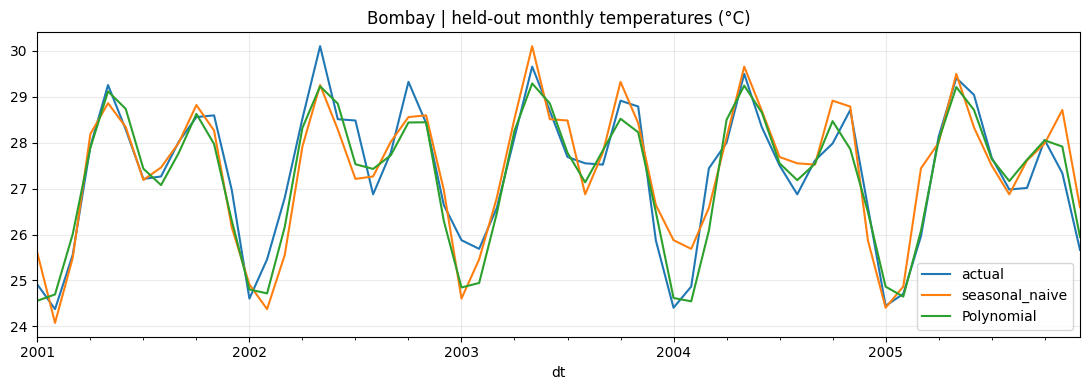

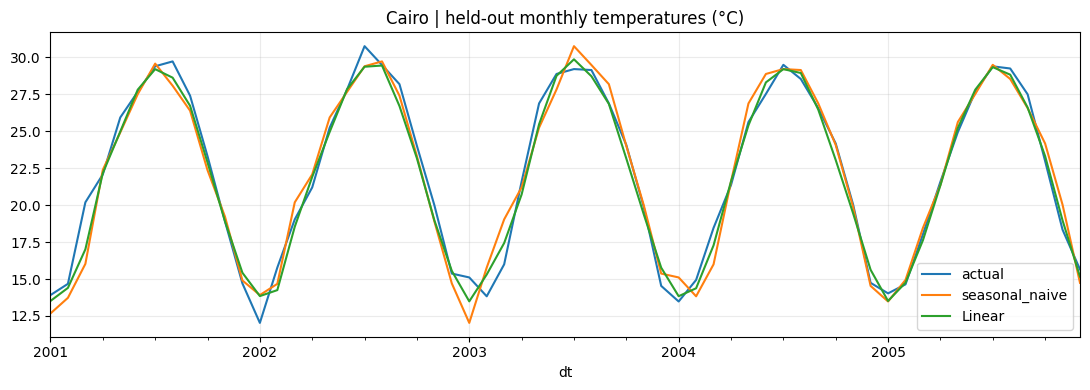

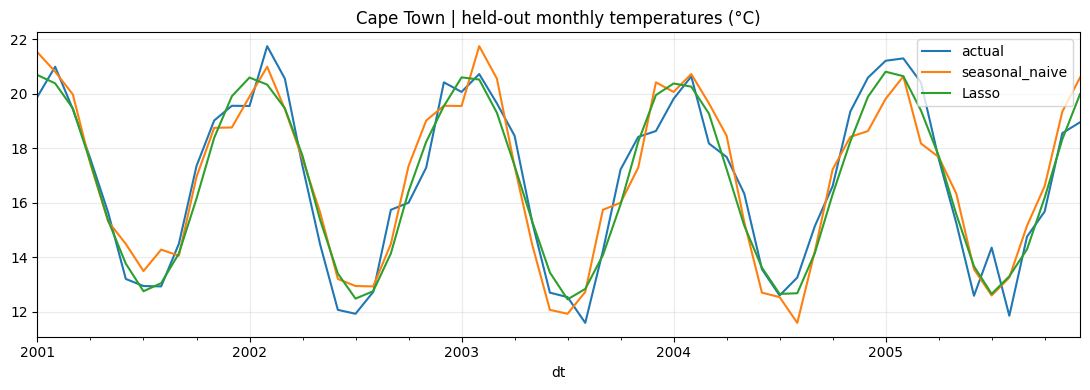

In [19]:
def forecasting_features(city):
    g=city.sort_values('dt').drop_duplicates('dt').set_index('dt').asfreq('MS')
    y=g.AverageTemperature
    f=pd.DataFrame({'target':y,'year':g.index.year,'sin_month':np.sin(2*np.pi*g.index.month/12),'cos_month':np.cos(2*np.pi*g.index.month/12)},index=g.index)
    for lag in [1,2,3,12]:f['lag_'+str(lag)]=y.shift(lag)
    f['rolling_12']=y.shift(1).rolling(12,min_periods=12).mean()
    return f.dropna()
reg_models={
 'Linear':(LinearRegression(),{}),
 'Ridge':(Ridge(),{'model__alpha':[.1,1,10]}),
 'Lasso':(Lasso(max_iter=10000),{'model__alpha':[.001,.01,.1]}),
 'Polynomial':(Ridge(),{'poly__degree':[2],'model__alpha':[1,10]}),
 'kNN':(KNeighborsRegressor(),{'model__n_neighbors':[3,7]}),
 'Decision tree':(DecisionTreeRegressor(random_state=SEED),{'model__max_depth':[4,8]}),
 'Random forest':(RandomForestRegressor(n_estimators=80,n_jobs=N_JOBS,random_state=SEED),{'model__max_depth':[5,None]}),
 'Gradient boosting':(GradientBoostingRegressor(random_state=SEED),{'model__n_estimators':[80,120]}),
 'SVR':(SVR(),{'model__C':[1,10]}),
 'MLP':(MLPRegressor(hidden_layer_sizes=(32,),max_iter=2500,tol=1e-3,random_state=SEED,early_stopping=False),{'model__alpha':[.001,.1]})}
# RUN_FULL_MODELS is configured near the top.
if not RUN_FULL_MODELS:
    reg_models={k:v for k,v in reg_models.items() if k in ['Linear','Ridge','Random forest']}
regression_predictions={}
REG_FITS={}
REG_CV_BEST={}
FORECAST_ROWS=[]
for (city,country),group in selected.groupby(['City','Country']):
    print(f'Forecasting {city}...', flush=True)
    f=forecasting_features(group)
    train=f.loc[:'2000-12-01'];test=f.loc['2001-01-01':'2013-12-01']
    if len(train)<60 or len(test)<100:print('Skipping insufficient coverage:',city);continue
    Xtr=train.drop(columns='target');ytr=train.target;Xte=test.drop(columns='target');yte=test.target
    cv=TimeSeriesSplit(n_splits=3)
    baseline=test.lag_12
    REGRESSION_ROWS.append(dict(city=city,model='Seasonal naive',params='-',cv_mean=np.nan,cv_sd=np.nan,MAE=mean_absolute_error(yte,baseline),RMSE=np.sqrt(mean_squared_error(yte,baseline)),R2=r2_score(yte,baseline),train_seconds=0,predict_seconds=0))
    regression_predictions[city]=pd.DataFrame({'actual':yte,'seasonal_naive':baseline},index=test.index)
    for name,(estimator,grid) in reg_models.items():
        print(f'  {city}: {name}', flush=True)
        steps=[('scale',StandardScaler())]
        if name=='Polynomial':steps.append(('poly',PolynomialFeatures(include_bias=False)))
        steps.append(('model',estimator));pipe=Pipeline(steps)
        search=GridSearchCV(pipe,grid or {},cv=cv,scoring='neg_mean_absolute_error',n_jobs=N_JOBS)
        tic=time.perf_counter()
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always',ConvergenceWarning)
            search.fit(Xtr,ytr)
        train_s=time.perf_counter()-tic
        FIT_WARNINGS.append(dict(task='monthly forecast',city=city,model=name,
            convergence_warnings=sum(issubclass(w.category,ConvergenceWarning) for w in caught)))
        REG_FITS[(city,name)]=search
        tic=time.perf_counter();pred=search.predict(Xte);pred_s=time.perf_counter()-tic
        REGRESSION_ROWS.append(dict(city=city,model=name,params=str(search.best_params_),cv_mean=-search.best_score_,cv_sd=search.cv_results_['std_test_score'][search.best_index_],MAE=mean_absolute_error(yte,pred),RMSE=np.sqrt(mean_squared_error(yte,pred)),R2=r2_score(yte,pred),train_seconds=train_s,predict_seconds=pred_s))
        regression_predictions[city][name]=pred
    best_name=min(reg_models,key=lambda name: -REG_FITS[(city,name)].best_score_)
    REG_CV_BEST[city]=best_name
    for stamp,actual,prediction in zip(test.index,yte,regression_predictions[city][best_name]):
        FORECAST_ROWS.append(dict(city=city,date=str(stamp.date()),model=best_name,actual=float(actual),prediction=float(prediction)))
regression_table=pd.DataFrame(REGRESSION_ROWS)
naive_metrics=regression_table[regression_table.model=='Seasonal naive'].set_index('city')
regression_table['MAE_skill']=1-regression_table.MAE/regression_table.city.map(naive_metrics.MAE)
regression_table['RMSE_skill']=1-regression_table.RMSE/regression_table.city.map(naive_metrics.RMSE)
pd.DataFrame(FORECAST_ROWS).to_csv(OUT/'phase3_cv_selected_predictions.csv',index=False)
display(regression_table)
regression_table.to_csv(OUT/'phase3_regression_comparison.csv',index=False)
for city in list(regression_predictions)[:3]:
    f=regression_predictions[city]
    best=regression_table[(regression_table.city==city)&(regression_table.model!='Seasonal naive')].sort_values('cv_mean').iloc[0]['model']
    f[['actual','seasonal_naive',best]].iloc[:60].plot(figsize=(11,4),title=f'{city} | held-out monthly temperatures (°C)')
    save_fig('phase3_forecast_'+city.replace(' ','_')+'.png')

assert regression_table.city.nunique()==10, 'All ten cities must complete the forecast comparison'


### 6.3. Twelve-month-ahead city forecasting
Uses lagged observations known at the forecast origin, with an eleven-month purge before validation and final holdout.

In [20]:
# Twelve-month-ahead forecasts: information no newer than target month minus 12.
horizon_rows=[]
for (city,country),group in selected.groupby(['City','Country']):
    series=group.sort_values('dt').drop_duplicates('dt').set_index('dt').AverageTemperature.asfreq('MS')
    f=pd.DataFrame({'target':series,'year':series.index.year,
        'sin_month':np.sin(2*np.pi*series.index.month/12),
        'cos_month':np.cos(2*np.pi*series.index.month/12)},index=series.index)
    for lag in [12,13,14,24]: f[f'lag_{lag}']=series.shift(lag)
    f['rolling12_at_origin']=series.shift(12).rolling(12,min_periods=12).mean()
    f=f.dropna()
    # Purge the 11 months whose labels were unavailable at first test forecast origin.
    train=f.loc[:'2000-01-01'];test=f.loc['2001-01-01':'2013-12-01']
    Xtrain=train.drop(columns='target');Xtest=test.drop(columns='target')
    fit=GridSearchCV(Pipeline([('scale',StandardScaler()),('model',Ridge())]),
        {'model__alpha':[.1,1,10]},cv=TimeSeriesSplit(n_splits=3,gap=11),
        scoring='neg_mean_absolute_error',n_jobs=N_JOBS)
    tic=time.perf_counter();fit.fit(Xtrain,train.target);train_s=time.perf_counter()-tic
    tic=time.perf_counter();horizon_pred=fit.predict(Xtest);pred_s=time.perf_counter()-tic
    for name,pred in [('Seasonal naive',test.lag_12),('Ridge',horizon_pred)]:
        horizon_rows.append(dict(city=city,model=name,horizon_months=12,
            params=str(fit.best_params_) if name=='Ridge' else '-',
            cv_mean=-fit.best_score_ if name=='Ridge' else np.nan,
            cv_sd=fit.cv_results_['std_test_score'][fit.best_index_] if name=='Ridge' else np.nan,
            train_seconds=train_s if name=='Ridge' else 0.,predict_seconds=pred_s if name=='Ridge' else 0.,
            MAE=mean_absolute_error(test.target,pred),
            RMSE=np.sqrt(mean_squared_error(test.target,pred)),R2=r2_score(test.target,pred)))
    print('12-month horizon complete:',city,flush=True)
horizon_table=pd.DataFrame(horizon_rows)
assert horizon_table.city.nunique()==10
horizon_naive=horizon_table[horizon_table.model=='Seasonal naive'].set_index('city')
horizon_table['MAE_skill']=1-horizon_table.MAE/horizon_table.city.map(horizon_naive.MAE)
horizon_table['RMSE_skill']=1-horizon_table.RMSE/horizon_table.city.map(horizon_naive.RMSE)
display(horizon_table)
horizon_table.to_csv(OUT/'phase3_twelve_month_forecasts.csv',index=False)


12-month horizon complete: Bombay
12-month horizon complete: Cairo
12-month horizon complete: Cape Town
12-month horizon complete: La Plata
12-month horizon complete: London
12-month horizon complete: New York
12-month horizon complete: Paris
12-month horizon complete: Sydney
12-month horizon complete: São Paulo
12-month horizon complete: Tokyo


,city,model,horizon_months,params,cv_mean,cv_sd,train_seconds,predict_seconds,MAE,RMSE,R2,MAE_skill,RMSE_skill
0,Bombay,Seasonal naive,12,-,NaN,NaN,0.000000,0.000000,0.575092,0.731389,0.754715,0.000000,0.000000
1,Bombay,Ridge,12,{'model__alpha': 0.1},0.518497,0.006747,0.063867,0.000780,0.510069,0.638176,0.813252,0.113066,0.127447
2,Cairo,Seasonal naive,12,-,NaN,NaN,0.000000,0.000000,1.070408,1.354398,0.943488,0.000000,0.000000
3,Cairo,Ridge,12,{'model__alpha': 1},0.817819,0.010471,0.060194,0.000598,0.868541,1.104369,0.962427,0.188589,0.184605
4,Cape Town,Seasonal naive,12,-,NaN,NaN,0.000000,0.000000,0.777776,0.927191,0.906165,0.000000,0.000000
5,Cape Town,Ridge,12,{'model__alpha': 0.1},0.675533,0.048345,0.053437,0.000696,0.565005,0.700472,0.946444,0.273563,0.244522
6,La Plata,Seasonal naive,12,-,NaN,NaN,0.000000,0.000000,1.238914,1.589189,0.890655,0.000000,0.000000
7,La Plata,Ridge,12,{'model__alpha': 1},0.987253,0.068460,0.057903,0.000754,0.932305,1.184857,0.939218,0.247482,0.254426
8,London,Seasonal naive,12,-,NaN,NaN,0.000000,0.000000,1.434428,1.815225,0.870107,0.000000,0.000000
9,London,Ridge,12,{'model__alpha': 10},1.175842,0.052029,0.059042,0.000616,1.145705,1.461565,0.915791,0.201281,0.194830


### 6.4. Australian next-day rain classification


#### 6.4.1. Logistic regression
Balanced class weights; tune C 0.1 or 1. The shared function below evaluates this classifier separately for both rain and heat, tuning by F1 in calendar-based training folds.

#### 6.4.2. k-Nearest Neighbors classification
Tune 9 or 25 neighbors. The shared function below evaluates this classifier separately for both rain and heat, tuning by F1 in calendar-based training folds.

#### 6.4.3. Gaussian Naive Bayes
Gaussian likelihood reference; no grid hyperparameter. The shared function below evaluates this classifier separately for both rain and heat, tuning by F1 in calendar-based training folds.

#### 6.4.4. Support Vector Classification
Balanced class weights; tune C 0.1 or 1. Decision scores support ROC-AUC. The shared function below evaluates this classifier separately for both rain and heat, tuning by F1 in calendar-based training folds.

#### 6.4.5. Decision tree classification
Balanced class weights; tune depth 5 or 10. The shared function below evaluates this classifier separately for both rain and heat, tuning by F1 in calendar-based training folds.

#### 6.4.6. Random forest classification
100 trees, balanced class weights; tune depth 8 or unrestricted. The shared function below evaluates this classifier separately for both rain and heat, tuning by F1 in calendar-based training folds.

#### 6.4.7. Gradient boosting classification
Tune 75 or 125 estimators. The shared function below evaluates this classifier separately for both rain and heat, tuning by F1 in calendar-based training folds.

#### 6.4.8. Multilayer perceptron classification
32 hidden units; tune alpha 0.001 or 0.1; 1,500-iteration budget and convergence audit. The shared function below evaluates this classifier separately for both rain and heat, tuning by F1 in calendar-based training folds.

Training sample 24000 of 116219 held-out 25974
Australia rain: training Logistic...
  complete: CV F1=0.633; test F1=0.617; 2.9s
Australia rain: training kNN...
  complete: CV F1=0.519; test F1=0.529; 1.8s
Australia rain: training Naive Bayes...
  complete: CV F1=0.486; test F1=0.463; 0.3s
Australia rain: training SVM...
  complete: CV F1=0.645; test F1=0.640; 66.4s
Australia rain: training Decision tree...
  complete: CV F1=0.573; test F1=0.569; 0.8s
Australia rain: training Random forest...
  complete: CV F1=0.622; test F1=0.597; 3.9s
Australia rain: training Gradient boosting...
  complete: CV F1=0.585; test F1=0.582; 24.0s
Australia rain: training MLP...
  complete: CV F1=0.621; test F1=0.627; 14.3s


,task,model,params,cv_mean,cv_sd,precision,recall,F1,ROC_AUC,train_seconds,predict_seconds,iterations,iteration_limit_reached
0,Australia rain,Logistic,{'model__C': 0.1},0.632831,0.013300,0.526930,0.743693,0.616822,0.855634,2.869737,0.155909,NaN,NaN
1,Australia rain,kNN,{'model__n_neighbors': 9},0.518671,0.022922,0.703125,0.423814,0.528856,0.826376,1.762891,2.761961,NaN,NaN
2,Australia rain,Naive Bayes,{},0.485928,0.021664,0.347727,0.692062,0.462880,0.719922,0.347864,0.115513,NaN,NaN
3,Australia rain,SVM,{'model__C': 1},0.644579,0.009689,0.549861,0.766902,0.640494,0.869187,66.390570,20.534774,NaN,NaN
4,Australia rain,Decision tree,{'model__max_depth': 5},0.572610,0.013856,0.462639,0.739321,0.569135,0.819560,0.806536,0.042911,NaN,NaN
5,Australia rain,Random forest,{'model__max_depth': 8},0.621602,0.012164,0.510633,0.718803,0.597094,0.838716,3.904700,0.103615,NaN,NaN
6,Australia rain,Gradient boosting,{'model__n_estimators': 125},0.585112,0.023735,0.733299,0.481837,0.581549,0.856901,23.978213,0.102975,NaN,NaN
7,Australia rain,MLP,{'model__alpha': 0.1},0.621186,0.023146,0.724465,0.552304,0.626777,0.873717,14.309918,0.063186,50.0,False


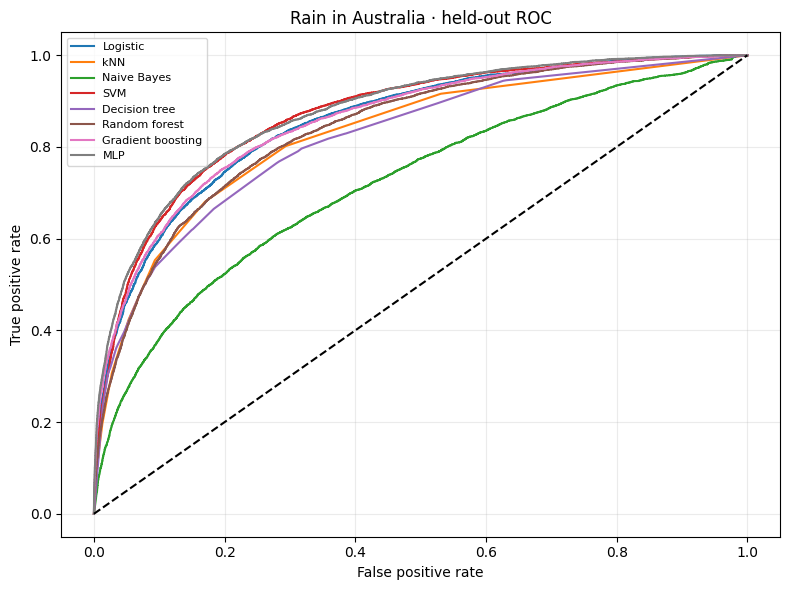

In [21]:
rainframe=rain.copy()
rainframe=rainframe[rainframe.RainTomorrow.isin(['Yes','No'])].copy()
rainframe['label']=(rainframe.RainTomorrow=='Yes').astype(int)
# RainTomorrow is not used as a feature. Rainfall today is valid, while any future-proxy fields must be excluded.
excluded={'RainTomorrow','label','Date','RISK_MM','RainfallTomorrow'}
columns=[c for c in rainframe if c not in excluded]
train=rainframe[rainframe.Date.dt.year<=2015].dropna(subset=['label'])
test=rainframe[rainframe.Date.dt.year>=2016].dropna(subset=['label'])
assert not train.empty and not test.empty
numerical=train[columns].select_dtypes(include=np.number).columns.tolist()
categorical=[c for c in columns if c not in numerical]
pre=ColumnTransformer([('num',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),numerical),('cat',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('encode',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),categorical)])
classification_models={
 'Logistic':(LogisticRegression(max_iter=1200,class_weight='balanced'),{'model__C':[.1,1]}),
 'kNN':(KNeighborsClassifier(),{'model__n_neighbors':[9,25]}),
 'Naive Bayes':(GaussianNB(),{}),
 'SVM':(SVC(class_weight='balanced',probability=False,cache_size=512,random_state=SEED),{'model__C':[.1,1]}),
 'Decision tree':(DecisionTreeClassifier(random_state=SEED,class_weight='balanced'),{'model__max_depth':[5,10]}),
 'Random forest':(RandomForestClassifier(n_estimators=100,random_state=SEED,class_weight='balanced',n_jobs=N_JOBS),{'model__max_depth':[8,None]}),
 'Gradient boosting':(GradientBoostingClassifier(random_state=SEED),{'model__n_estimators':[75,125]}),
 'MLP':(MLPClassifier(hidden_layer_sizes=(32,),max_iter=1500,tol=1e-3,random_state=SEED),{'model__alpha':[.001,.1]})}
if not RUN_FULL_MODELS:
    classification_models={k:v for k,v in classification_models.items() if k in ['Logistic','Naive Bayes','Random forest']}
CLASS_FITS={}
CLASS_PREDICTIONS={}
def class_run(train,test,feature_columns,transformer,task,cv):
    out=[];roc=[]
    for name,(model,grid) in classification_models.items():
        print(f'{task}: training {name}...', flush=True)
        pipe=Pipeline([('prep',transformer),('model',model)])
        fit=GridSearchCV(pipe,grid or {},cv=cv,scoring='f1',n_jobs=N_JOBS)
        start=time.perf_counter()
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always',ConvergenceWarning)
            fit.fit(train[feature_columns],train.label)
        train_s=time.perf_counter()-start
        FIT_WARNINGS.append(dict(task=task,city='',model=name,
            convergence_warnings=sum(issubclass(w.category,ConvergenceWarning) for w in caught)))
        start=time.perf_counter();pred=fit.predict(test[feature_columns]);pred_s=time.perf_counter()-start
        prob=(fit.predict_proba(test[feature_columns])[:,1] if hasattr(fit, 'predict_proba') else fit.decision_function(test[feature_columns]))
        CLASS_FITS[(task,name)]=fit
        CLASS_PREDICTIONS[(task,name)]=pred
        out.append(dict(task=task,model=name,params=str(fit.best_params_),cv_mean=fit.best_score_,cv_sd=fit.cv_results_['std_test_score'][fit.best_index_],precision=precision_score(test.label,pred,zero_division=0),recall=recall_score(test.label,pred,zero_division=0),F1=f1_score(test.label,pred,zero_division=0),ROC_AUC=roc_auc_score(test.label,prob),train_seconds=train_s,predict_seconds=pred_s))
        if name=='MLP':
            final_mlp=fit.best_estimator_.named_steps['model']
            out[-1]['iterations']=int(final_mlp.n_iter_)
            out[-1]['iteration_limit_reached']=bool(final_mlp.n_iter_>=final_mlp.max_iter)
        roc.append((name,prob))
        print(f'  complete: CV F1={fit.best_score_:.3f}; test F1={out[-1]["F1"]:.3f}; {train_s:.1f}s', flush=True)
    return pd.DataFrame(out),roc
# SVM on full 145k rows can be computationally expensive; deterministic chronological subsampling for tuning.
# Final holdout remains complete and untouched.
cap=24000
train_sample=train.sort_values(['Date','Location']).reset_index(drop=True)
if len(train_sample)>cap:
    # Use uniform temporal sampling without using test labels or future observations.
    ids=np.linspace(0,len(train_sample)-1,cap,dtype=int);train_sample=train_sample.iloc[ids]
print('Training sample',len(train_sample),'of',len(train),'held-out',len(test))
rain_scores,rain_roc=class_run(train_sample,test,columns,pre,'Australia rain',calendar_cv(train_sample,n_splits=3))
display(rain_scores);rain_scores.to_csv(OUT/'phase5_rain_comparison.csv',index=False)
fig,ax=plt.subplots(figsize=(8,6))
from sklearn.metrics import roc_curve
for name,p in rain_roc:
    fpr,tpr,_=roc_curve(test.label,p);ax.plot(fpr,tpr,label=name)
ax.plot([0,1],[0,1],'k--');ax.legend(fontsize=8);ax.set(xlabel='False positive rate',ylabel='True positive rate',title='Rain in Australia · held-out ROC')
save_fig('phase5_rain_roc.png')


### 6.5. Puerto Rico next-day heat classification


Local heat: training Logistic...
  complete: CV F1=0.303; test F1=0.428; 0.3s
Local heat: training kNN...
  complete: CV F1=0.146; test F1=0.392; 0.4s
Local heat: training Naive Bayes...
  complete: CV F1=0.293; test F1=0.431; 0.1s
Local heat: training SVM...
  complete: CV F1=0.295; test F1=0.454; 3.2s
Local heat: training Decision tree...
  complete: CV F1=0.299; test F1=0.448; 0.2s
Local heat: training Random forest...
  complete: CV F1=0.326; test F1=0.493; 2.5s
Local heat: training Gradient boosting...
  complete: CV F1=0.279; test F1=0.429; 3.0s
Local heat: training MLP...
  complete: CV F1=0.110; test F1=0.324; 2.2s
Annual trend includes years with at least 90% observed tmax coverage: 25
Full-record 90th percentile of tmax (°C): 32.2 trend heat days/year: 0.8455468491336647
Heat-rate slope (percentage points/year): 0.22029009936735283
Full-record and training-period thresholds: 32.2 32.2


,task,model,params,cv_mean,cv_sd,precision,recall,F1,ROC_AUC,train_seconds,predict_seconds,iterations,iteration_limit_reached
0,Local heat,Logistic,{'model__C': 1},0.303255,0.029378,0.282051,0.885593,0.427840,0.875866,0.272874,0.032556,NaN,NaN
1,Local heat,kNN,{'model__n_neighbors': 9},0.145752,0.094186,0.612613,0.288136,0.391931,0.817729,0.359779,0.058121,NaN,NaN
2,Local heat,Naive Bayes,{},0.293060,0.036869,0.289898,0.838983,0.430903,0.859088,0.083793,0.014005,NaN,NaN
3,Local heat,SVM,{'model__C': 1},0.294775,0.031883,0.300824,0.927966,0.454357,0.869356,3.209986,0.241476,NaN,NaN
4,Local heat,Decision tree,{'model__max_depth': 5},0.298765,0.035795,0.302671,0.864407,0.448352,0.862087,0.221343,0.014872,NaN,NaN
5,Local heat,Random forest,{'model__max_depth': 8},0.326279,0.057294,0.361829,0.771186,0.492558,0.877740,2.500219,0.037882,NaN,NaN
6,Local heat,Gradient boosting,{'model__n_estimators': 125},0.278857,0.062088,0.644068,0.322034,0.429379,0.885104,2.957869,0.016061,NaN,NaN
7,Local heat,MLP,{'model__alpha': 0.001},0.110442,0.089827,0.684932,0.211864,0.323625,0.876274,2.184353,0.014765,29.0,False


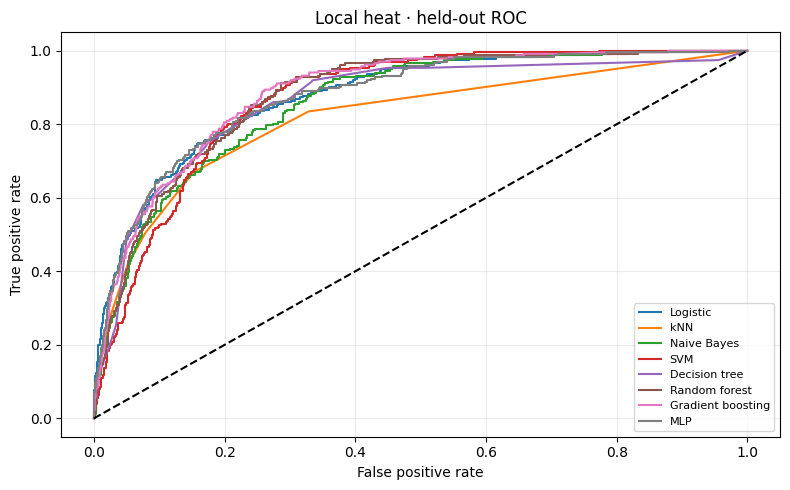

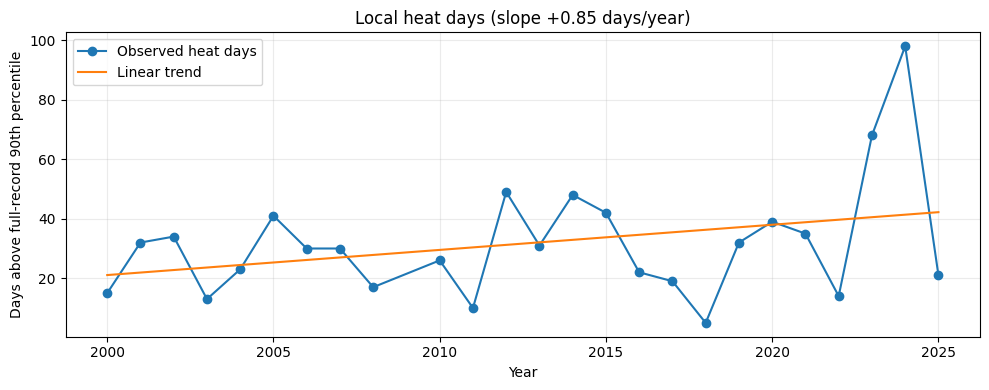

In [22]:
if station is None or station.empty:
    print('Local station data unavailable; download a verified 20-year daily record and rerun Phase 1.')
else:
    daily=station.copy().set_index('time').sort_index().asfreq('D')
    daily['tmax']=pd.to_numeric(daily['tmax'],errors='coerce')
    if (daily.index.max()-daily.index.min()).days<365*20:raise ValueError('At least 20 years of local daily data required')
    cutoff=int(daily.index.year.max()-5)
    heat_threshold=daily.tmax.quantile(.90)
    training_threshold=daily.loc[daily.index.year<=cutoff,'tmax'].quantile(.90)
    daily['label']=(daily.tmax>heat_threshold).astype(float);daily.loc[daily.tmax.isna(),'label']=np.nan
    for lag in [1,2,3,7]:daily[f'tmax_lag{lag}']=daily.tmax.shift(lag)
    daily['tmax_roll7']=daily.tmax.shift(1).rolling(7).mean()
    for var in ['tmin','prcp']:
        if var in daily:daily[var+'_lag1']=daily[var].shift(1)
    daily['month_sin']=np.sin(2*np.pi*daily.index.month/12);daily['month_cos']=np.cos(2*np.pi*daily.index.month/12)
    features=[x for x in daily if x.startswith(('tmax_lag','tmax_roll','tmin_lag','prcp_lag','month_'))]
    heat=daily[features+['label']].reset_index().rename(columns={'time':'Date'}).dropna(subset=['label'])
    ht=heat[heat.Date.dt.year<=cutoff];hv=heat[heat.Date.dt.year>cutoff]
    local_transform=ColumnTransformer([('num',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),features)])
    heat_scores,heat_roc=class_run(ht,hv,features,local_transform,'Local heat',calendar_cv(ht,n_splits=4))
    display(heat_scores);heat_scores.to_csv(OUT/'phase5_heat_comparison.csv',index=False)
    fig,ax=plt.subplots(figsize=(8,5))
    for name,p in heat_roc:
        fpr,tpr,_=roc_curve(hv.label,p);ax.plot(fpr,tpr,label=name)
    ax.plot([0,1],[0,1],'k--');ax.legend(fontsize=8);ax.set(xlabel='False positive rate',ylabel='True positive rate',title='Local heat · held-out ROC');save_fig('phase5_heat_roc.png')
    annual_heat=daily.groupby(daily.index.year).agg(heat_days=('label','sum'),observed=('label','count'))
    annual_heat['calendar_days']=pd.Series(daily.index.year,index=daily.index).groupby(daily.index.year).size()
    annual_heat['coverage']=annual_heat.observed/annual_heat.calendar_days
    annual_heat['heat_rate']=annual_heat.heat_days/annual_heat.observed
    annual_heat.to_csv(OUT/'phase5_annual_heat_coverage_all_years.csv')
    annual_heat=annual_heat[annual_heat.coverage>=.90].copy()
    print('Annual trend includes years with at least 90% observed tmax coverage:',len(annual_heat))
    slope,intercept=np.polyfit(annual_heat.index,annual_heat.heat_days,1)
    ax=annual_heat.heat_days.plot(figsize=(10,4),marker='o',label='Observed heat days')
    ax.plot(annual_heat.index,slope*annual_heat.index+intercept,label='Linear trend');ax.legend()
    ax.set(xlabel='Year',ylabel='Days above full-record 90th percentile',title=f'Local heat days (slope {slope:+.2f} days/year)');save_fig('phase5_heat_trend.png')
    print('Full-record 90th percentile of tmax (°C):',heat_threshold,'trend heat days/year:',slope)

    annual_heat.to_csv(OUT/'phase5_annual_heat_days.csv')
    heat_rate_trend=linregress(annual_heat.index,annual_heat.heat_rate)
    print('Heat-rate slope (percentage points/year):',heat_rate_trend.slope*100)
    print('Full-record and training-period thresholds:',heat_threshold,training_threshold)
    assert heat_threshold==daily.tmax.quantile(.90)


## 7. Model comparison table and plots
Tables display best hyperparameters, cross-validation mean/SD, held-out metrics, and training/prediction times. All metrics below are computed from observed data after successful training. For Phase 5, per-location accuracy and confusion matrices are additionally required by the assignment.

In [23]:
if REGRESSION_ROWS:
    display(regression_table.groupby('model')[['MAE','RMSE','R2']].mean().sort_values('MAE'))
if 'rain_scores' in globals():
    display(rain_scores.sort_values('F1',ascending=False))
    # Choose the reporting model using validation only, then use cached test predictions.
    best_name=rain_scores.sort_values('cv_mean',ascending=False).iloc[0]['model']
    predictions=CLASS_PREDICTIONS[('Australia rain',best_name)]
    print('Rain reporting model selected by CV:',best_name)
    print('Rain confusion matrix:');display(pd.DataFrame(confusion_matrix(test.label,predictions),index=['Actual No','Actual Yes'],columns=['Pred No','Pred Yes']))
    by_location=test[['Location','label']].copy();by_location['correct']=(predictions==test.label.to_numpy())
    display(by_location.groupby('Location').correct.agg(['mean','count']).sort_values('mean'))
if 'heat_scores' in globals():display(heat_scores.sort_values('F1',ascending=False))

if 'rain_scores' in globals():
    by_location.groupby('Location').correct.agg(['mean','count']).to_csv(OUT/'phase5_rain_per_location.csv')
if 'heat_scores' in globals():
    heat_best=heat_scores.sort_values('cv_mean',ascending=False).iloc[0]['model']
    print('Heat reporting model selected by CV:',heat_best)
    heat_pred=CLASS_PREDICTIONS[('Local heat',heat_best)]
    display(pd.DataFrame(confusion_matrix(hv.label,heat_pred),index=['Actual No','Actual Yes'],columns=['Pred No','Pred Yes']))


Rain reporting model selected by CV: SVM
Rain confusion matrix:
Heat reporting model selected by CV: Random forest


,MAE,RMSE,R2
model,,,
Polynomial,0.829223,1.052128,0.925910
Linear,0.870728,1.112121,0.914671
Ridge,0.870939,1.111818,0.914797
Lasso,0.873399,1.114234,0.914250
SVR,0.919747,1.158498,0.910926
MLP,0.924128,1.175918,0.891331
kNN,0.924422,1.166972,0.910797
Gradient boosting,0.935396,1.178006,0.912834
Random forest,0.963878,1.201918,0.908963


,task,model,params,cv_mean,cv_sd,precision,recall,F1,ROC_AUC,train_seconds,predict_seconds,iterations,iteration_limit_reached
3,Australia rain,SVM,{'model__C': 1},0.644579,0.009689,0.549861,0.766902,0.640494,0.869187,66.390570,20.534774,NaN,NaN
7,Australia rain,MLP,{'model__alpha': 0.1},0.621186,0.023146,0.724465,0.552304,0.626777,0.873717,14.309918,0.063186,50.0,False
0,Australia rain,Logistic,{'model__C': 0.1},0.632831,0.013300,0.526930,0.743693,0.616822,0.855634,2.869737,0.155909,NaN,NaN
5,Australia rain,Random forest,{'model__max_depth': 8},0.621602,0.012164,0.510633,0.718803,0.597094,0.838716,3.904700,0.103615,NaN,NaN
6,Australia rain,Gradient boosting,{'model__n_estimators': 125},0.585112,0.023735,0.733299,0.481837,0.581549,0.856901,23.978213,0.102975,NaN,NaN
4,Australia rain,Decision tree,{'model__max_depth': 5},0.572610,0.013856,0.462639,0.739321,0.569135,0.819560,0.806536,0.042911,NaN,NaN
1,Australia rain,kNN,{'model__n_neighbors': 9},0.518671,0.022922,0.703125,0.423814,0.528856,0.826376,1.762891,2.761961,NaN,NaN
2,Australia rain,Naive Bayes,{},0.485928,0.021664,0.347727,0.692062,0.462880,0.719922,0.347864,0.115513,NaN,NaN


,Pred No,Pred Yes
Actual No,16295,3733
Actual Yes,1386,4560


,mean,count
Location,,
Cairns,0.661943,494
CoffsHarbour,0.669742,542
NorfolkIsland,0.684739,498
Williamtown,0.710372,511
NorahHead,0.715342,541
Launceston,0.724907,538
GoldCoast,0.728880,509
Portland,0.729128,539
Walpole,0.732314,523


,task,model,params,cv_mean,cv_sd,precision,recall,F1,ROC_AUC,train_seconds,predict_seconds,iterations,iteration_limit_reached
5,Local heat,Random forest,{'model__max_depth': 8},0.326279,0.057294,0.361829,0.771186,0.492558,0.877740,2.500219,0.037882,NaN,NaN
3,Local heat,SVM,{'model__C': 1},0.294775,0.031883,0.300824,0.927966,0.454357,0.869356,3.209986,0.241476,NaN,NaN
4,Local heat,Decision tree,{'model__max_depth': 5},0.298765,0.035795,0.302671,0.864407,0.448352,0.862087,0.221343,0.014872,NaN,NaN
2,Local heat,Naive Bayes,{},0.293060,0.036869,0.289898,0.838983,0.430903,0.859088,0.083793,0.014005,NaN,NaN
6,Local heat,Gradient boosting,{'model__n_estimators': 125},0.278857,0.062088,0.644068,0.322034,0.429379,0.885104,2.957869,0.016061,NaN,NaN
0,Local heat,Logistic,{'model__C': 1},0.303255,0.029378,0.282051,0.885593,0.427840,0.875866,0.272874,0.032556,NaN,NaN
1,Local heat,kNN,{'model__n_neighbors': 9},0.145752,0.094186,0.612613,0.288136,0.391931,0.817729,0.359779,0.058121,NaN,NaN
7,Local heat,MLP,{'model__alpha': 0.001},0.110442,0.089827,0.684932,0.211864,0.323625,0.876274,2.184353,0.014765,29.0,False


,Pred No,Pred Yes
Actual No,1269,321
Actual Yes,54,182


In [24]:
# One task-labelled comparison table; different scores/units are not ranked together.
master_parts=[]
def tagged(frame,task,cv_metric,horizon=np.nan):
    f=frame.copy();f['task']=task;f['cv_metric']=cv_metric;f['horizon_months']=horizon
    return f
master_parts.append(tagged(phase2_table,'global temperature','MAE (°C)'))
master_parts.append(tagged(regression_table,'city temperature','MAE (°C)',1))
master_parts.append(tagged(horizon_table,'city temperature','MAE (°C)',12))
master_parts.append(tagged(rain_scores,'Australia rain','F1'))
master_parts.append(tagged(heat_scores,'Puerto Rico heat: full-record threshold','F1'))
master_parts.append(pd.DataFrame([
 {'task':'climate structure','model':'PCA','params':'n_components=2','explained_variance':float(components.explained_variance_ratio_.sum()),'evaluation_scope':'descriptive fit on 20 city profiles'},
 {'task':'climate structure','model':'K-Means','params':f'k={best_k}; n_init=20; seed=42','silhouette':float(clust_diag.loc[clust_diag.k==best_k,'silhouette'].iloc[0]),'adjusted_rand':float(koppen_ari),'evaluation_scope':'descriptive fit on 20 city profiles'}]))
master=pd.concat(master_parts,ignore_index=True)
master.to_csv(OUT/'master_model_comparison.csv',index=False)
display(master)
display(Markdown('**Table notes.** Regression CV columns are positive MAE in °C (lower is better); classification CV is F1 (higher is better). CV SD describes fold variation, not a confidence interval. Training time includes search and final refit; prediction time covers point predictions only. Seasonal-naive baselines have no training/search cost. Unsupervised rows are descriptive rather than held-out prediction experiments. Positive baseline skill means lower error than seasonal naive on identical target dates.'))
# Convergence evidence includes all grid fits and the selected final estimator.
convergence=pd.DataFrame(FIT_WARNINGS)
selected_iterations=[]
for (city,name),fit in REG_FITS.items():
    if name=='MLP':
        model=fit.best_estimator_.named_steps['model']
        selected_iterations.append(dict(task='monthly forecast',city=city,model=name,iterations=int(model.n_iter_),limit=int(model.max_iter),iteration_limit_reached=bool(model.n_iter_>=model.max_iter)))
for (task,name),fit in CLASS_FITS.items():
    if name=='MLP':
        model=fit.best_estimator_.named_steps['model']
        selected_iterations.append(dict(task=task,city='',model=name,iterations=int(model.n_iter_),limit=int(model.max_iter),iteration_limit_reached=bool(model.n_iter_>=model.max_iter)))
selected_iterations=pd.DataFrame(selected_iterations)
convergence.to_csv(OUT/'convergence_search_warnings.csv',index=False)
selected_iterations.to_csv(OUT/'convergence_selected_models.csv',index=False)
display(selected_iterations)

,task,model,with_co2,train_start,train_end,test_start,test_end,params,cv_mean,cv_sd,MAE,RMSE,R2,train_seconds,predict_seconds,cv_metric,horizon_months,city,MAE_skill,RMSE_skill,precision,recall,F1,ROC_AUC,iterations,iteration_limit_reached,explained_variance,evaluation_scope,silhouette,adjusted_rand
0,global temperature,Linear trend,False,1850.0,2000.0,2001.0,2015.0,{},0.182032,0.042206,0.320942,0.328474,-16.661862,0.025792,0.001127,MAE (°C),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,global temperature,Polynomial trend degree 2,False,1850.0,2000.0,2001.0,2015.0,{},0.324505,0.227196,0.146633,0.160774,-3.231252,0.032444,0.001193,MAE (°C),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,global temperature,Polynomial trend degree 3,False,1850.0,2000.0,2001.0,2015.0,{},0.478969,0.222177,0.171223,0.183569,-4.516107,0.023086,0.000979,MAE (°C),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,global temperature,Ridge,False,1958.0,2000.0,2001.0,2015.0,{'reg__alpha': 1},0.130218,0.049408,0.160899,0.173988,-3.955361,0.100026,0.001144,MAE (°C),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,global temperature,Lasso,False,1958.0,2000.0,2001.0,2015.0,{'reg__alpha': 0.01},0.131209,0.039433,0.178066,0.190019,-4.910569,0.120582,0.001074,MAE (°C),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
150,Puerto Rico heat: full-record threshold,Random forest,NaN,NaN,NaN,NaN,NaN,{'model__max_depth': 8},0.326279,0.057294,NaN,NaN,NaN,2.500219,0.037882,F1,NaN,NaN,NaN,NaN,0.361829,0.771186,0.492558,0.877740,NaN,NaN,NaN,NaN,NaN,NaN
151,Puerto Rico heat: full-record threshold,Gradient boosting,NaN,NaN,NaN,NaN,NaN,{'model__n_estimators': 125},0.278857,0.062088,NaN,NaN,NaN,2.957869,0.016061,F1,NaN,NaN,NaN,NaN,0.644068,0.322034,0.429379,0.885104,NaN,NaN,NaN,NaN,NaN,NaN
152,Puerto Rico heat: full-record threshold,MLP,NaN,NaN,NaN,NaN,NaN,{'model__alpha': 0.001},0.110442,0.089827,NaN,NaN,NaN,2.184353,0.014765,F1,NaN,NaN,NaN,NaN,0.684932,0.211864,0.323625,0.876274,29.0,False,NaN,NaN,NaN,NaN
153,climate structure,PCA,NaN,NaN,NaN,NaN,NaN,n_components=2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.965911,descriptive fit on 20 city profiles,NaN,NaN


**Table notes.** Regression CV columns are positive MAE in °C (lower is better); classification CV is F1 (higher is better). CV SD describes fold variation, not a confidence interval. Training time includes search and final refit; prediction time covers point predictions only. Seasonal-naive baselines have no training/search cost. Unsupervised rows are descriptive rather than held-out prediction experiments. Positive baseline skill means lower error than seasonal naive on identical target dates.

,task,city,model,iterations,limit,iteration_limit_reached
0,monthly forecast,Bombay,MLP,509,2500,False
1,monthly forecast,Cairo,MLP,439,2500,False
2,monthly forecast,Cape Town,MLP,525,2500,False
3,monthly forecast,La Plata,MLP,581,2500,False
4,monthly forecast,London,MLP,198,2500,False
5,monthly forecast,New York,MLP,252,2500,False
6,monthly forecast,Paris,MLP,302,2500,False
7,monthly forecast,Sydney,MLP,433,2500,False
8,monthly forecast,São Paulo,MLP,523,2500,False
9,monthly forecast,Tokyo,MLP,194,2500,False


## 8. Interpretation, feature importance and error analysis
After running all cells: interpret the dominant PCA loadings (warmth/seasonality), the Köppen agreement, model-versus-seasonal-naive skill, per-location rain performance, and whether observed heat days are increasing. Forecast errors and test scores must be discussed with the actual values shown in Section 7. A high CO₂–temperature correlation does **not** independently prove causation.

Out[0]: 641


,,MAE,bias,max_absolute_error
city,model,,,
Bombay,Polynomial,0.442356,0.122316,1.504383
Cairo,Linear,0.793534,0.323789,3.181752
Cape Town,Lasso,0.568297,0.044061,1.696197
La Plata,Lasso,0.938619,0.179798,3.498597
London,Ridge,1.012854,0.419564,3.676875
New York,Lasso,1.304981,0.456201,4.931265
Paris,Ridge,1.276637,0.475239,4.484568
Sydney,Lasso,0.580238,0.262686,2.436190
São Paulo,Polynomial,0.779306,0.220700,3.162310


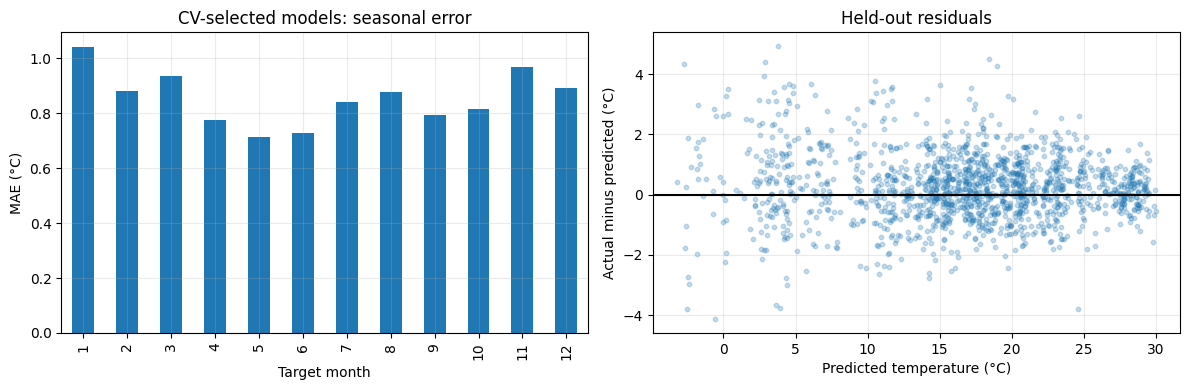

,task,feature,F1_decrease,repeat_sd
13,Australia rain,Humidity3pm,0.140705,0.015838
15,Australia rain,Pressure3pm,0.140480,0.006285
7,Australia rain,WindGustSpeed,0.097034,0.002293
2,Australia rain,MaxTemp,0.054446,0.004671
19,Australia rain,Temp3pm,0.033715,0.001678
14,Australia rain,Pressure9am,0.031743,0.007662
18,Australia rain,Temp9am,0.025303,0.002353
0,Australia rain,Location,0.021502,0.002905
9,Australia rain,WindDir3pm,0.017845,0.005246
1,Australia rain,MinTemp,0.015345,0.002580


,task,feature,F1_decrease,repeat_sd
0,Puerto Rico heat,tmax_lag1,0.174358,0.009884
4,Puerto Rico heat,tmax_roll7,0.056481,0.016479
5,Puerto Rico heat,tmin_lag1,0.028964,0.014544
8,Puerto Rico heat,month_cos,0.012297,0.019822
6,Puerto Rico heat,prcp_lag1,-0.001460,0.004241
2,Puerto Rico heat,tmax_lag3,-0.003474,0.004659
3,Puerto Rico heat,tmax_lag7,-0.010445,0.007618
7,Puerto Rico heat,month_sin,-0.014024,0.002198
1,Puerto Rico heat,tmax_lag2,-0.017556,0.008574


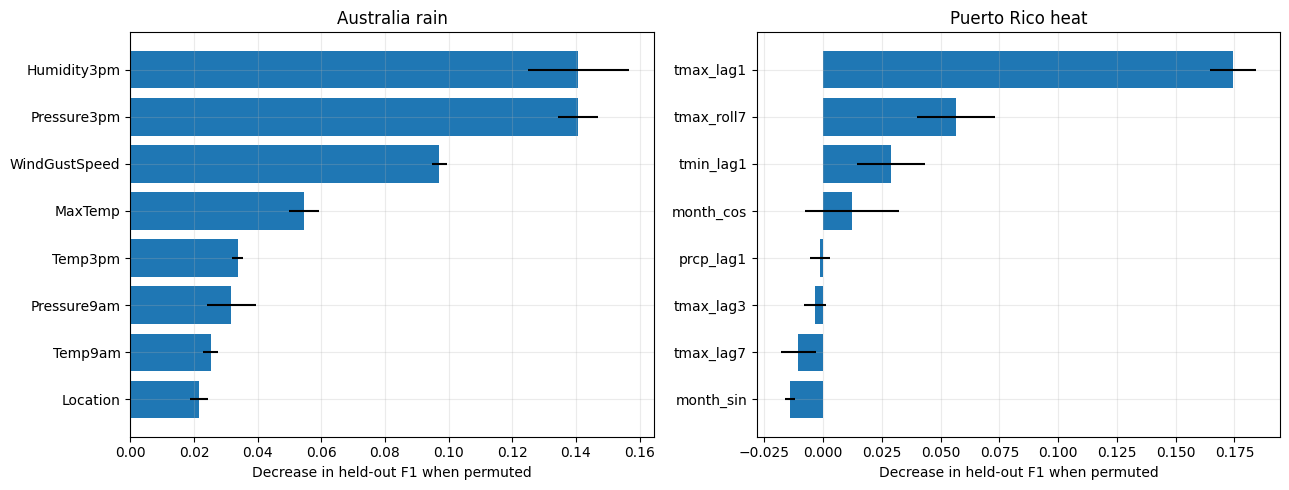

**Rain errors:** 3,733 false positives and 1,386 false negatives; positive-class recall is 76.7%. False-negative events are relevant when considering warnings, while false positives create unnecessary alerts.

**Heat errors:** 321 false positives and 54 false negatives; positive-class recall is 77.1%. False-negative events are relevant when considering warnings, while false positives create unnecessary alerts.

**Q1 — Warming.** The descriptive full-record slopes are 0.0360°C/decade before 1975 and 0.1642°C/decade afterward. The ordinary regression intervals do not correct serial correlation.

**Q2 — Forecasting.** CV-selected one-month models average 0.855°C city MAE. Twelve-month Ridge forecasts have a mean per-city MAE skill of 21.3% relative to the same-month-last-year baseline; this is a retrospective twelve-month lead experiment, not a single fixed-origin forecast of the whole test period.

**Q3 — Climate structure.** The first two PCs explain 96.6% of standardized-profile variance; k=3 has the best tested silhouette. ARI=0.0596 indicates weak agreement with the detailed Köppen labels, so these temperature-based clusters should not be described as recovered Köppen classes. PC1 loads positively on monthly temperatures and negatively on annual range; PC2 distinguishes summer/seasonal patterns.

**Q4 — Events.** CV-selected SVM achieves rain F1=0.640, AUC=0.869; Random forest achieves heat F1=0.493, AUC=0.878. At the full-record 32.2°C threshold, annual counts change by +0.846 days/year and observed-day rates by +0.220 percentage points/year among years with at least 90% coverage. These descriptive trends are not causal attribution or clinical thresholds.

**Report discussion.** (1) CO₂–temperature association alone does not prove causation: shared time trends, physical mechanisms and competing influences must be assessed. (2) At longer lead times, recent weather information becomes unavailable and uncertainty grows; compare Ridge across the two horizons without claiming that all ten model families were tested at twelve months. (3) Instrument changes, station moves, changing coverage and missing data can bias trends; source uncertainty and observed-day coverage constrain interpretation. (4) A locally validated event model could inform staffing, cooling resources or energy planning, but these retrospective station scores do not justify deployment or campus-specific warnings.

In [25]:
# Reporting models chosen strictly by training CV, not the largest test score.
errors=pd.DataFrame(FORECAST_ROWS)
errors['residual']=errors.actual-errors.prediction
errors['absolute_error']=errors.residual.abs()
errors['month']=pd.to_datetime(errors.date).dt.month
errors.to_csv(OUT/'phase3_residuals.csv',index=False)
error_by_city=errors.groupby(['city','model']).agg(MAE=('absolute_error','mean'),bias=('residual','mean'),max_absolute_error=('absolute_error','max'))
display(error_by_city)
error_by_city.to_csv(OUT/'phase3_error_by_city.csv')
fig,axs=plt.subplots(1,2,figsize=(12,4))
errors.groupby('month').absolute_error.mean().plot.bar(ax=axs[0]);axs[0].set(xlabel='Target month',ylabel='MAE (°C)',title='CV-selected models: seasonal error')
axs[1].scatter(errors.prediction,errors.residual,alpha=.25,s=10);axs[1].axhline(0,color='black');axs[1].set(xlabel='Predicted temperature (°C)',ylabel='Actual minus predicted (°C)',title='Held-out residuals')
save_fig('phase3_residual_analysis.png')
# Permutation importance on raw columns of the held-out reporting pipeline.
# This is post-evaluation interpretation and is not used for tuning/selection.
importance_parts=[]
for task,fit,frame,cols in [
 ('Australia rain',CLASS_FITS[('Australia rain',best_name)],test,columns),
 ('Puerto Rico heat',CLASS_FITS[('Local heat',heat_best)],hv,features)]:
    audit_sample=frame.sample(n=min(1000,len(frame)),random_state=SEED)
    result=permutation_importance(fit.best_estimator_,audit_sample[cols],audit_sample.label,
        scoring='f1',n_repeats=3,random_state=SEED,n_jobs=N_JOBS)
    table=pd.DataFrame({'task':task,'feature':cols,'F1_decrease':result.importances_mean,'repeat_sd':result.importances_std})
    importance_parts.append(table)
    display(table.sort_values('F1_decrease',ascending=False).head(10))
importance=pd.concat(importance_parts,ignore_index=True)
importance.to_csv(OUT/'classification_permutation_importance.csv',index=False)
fig,axs=plt.subplots(1,2,figsize=(13,5))
for ax,task in zip(axs,['Australia rain','Puerto Rico heat']):
    part=importance[importance.task==task].nlargest(8,'F1_decrease').sort_values('F1_decrease')
    ax.barh(part.feature,part.F1_decrease,xerr=part.repeat_sd);ax.set(title=task,xlabel='Decrease in held-out F1 when permuted')
save_fig('phase5_feature_importance.png')
# Exact confusion matrices saved for report use.
for task,actual,pred in [('rain',test.label,predictions),('heat',hv.label,heat_pred)]:
    cm=confusion_matrix(actual,pred,labels=[0,1])
    pd.DataFrame(cm,index=['actual_no','actual_yes'],columns=['pred_no','pred_yes']).to_csv(OUT/f'phase5_{task}_confusion_matrix.csv')
    tn,fp,fn,tp=cm.ravel()
    display(Markdown(f'**{task.title()} errors:** {fp:,} false positives and {fn:,} false negatives; positive-class recall is {tp/(tp+fn):.1%}. False-negative events are relevant when considering warnings, while false positives create unnecessary alerts.'))
cv_selected=regression_table[regression_table.apply(lambda r:r.model==REG_CV_BEST[r.city],axis=1)]
mean_mae=float(cv_selected.MAE.mean())
rain_best_row=rain_scores.set_index('model').loc[best_name]
heat_best_row=heat_scores.set_index('model').loc[heat_best]
mean_horizon_skill=float(horizon_table[horizon_table.model=='Ridge'].MAE_skill.mean())
explained=float(components.explained_variance_ratio_.sum())
display(Markdown(f'**Q1 — Warming.** The descriptive full-record slopes are {MODEL_RESULTS[0]["value"]:.4f}°C/decade before 1975 and {MODEL_RESULTS[1]["value"]:.4f}°C/decade afterward. The ordinary regression intervals do not correct serial correlation.'))
display(Markdown(f'**Q2 — Forecasting.** CV-selected one-month models average {mean_mae:.3f}°C city MAE. Twelve-month Ridge forecasts have a mean per-city MAE skill of {mean_horizon_skill:.1%} relative to the same-month-last-year baseline; this is a retrospective twelve-month lead experiment, not a single fixed-origin forecast of the whole test period.'))
display(Markdown(f'**Q3 — Climate structure.** The first two PCs explain {explained:.1%} of standardized-profile variance; k={best_k} has the best tested silhouette. ARI={koppen_ari:.4f} indicates weak agreement with the detailed Köppen labels, so these temperature-based clusters should not be described as recovered Köppen classes. PC1 loads positively on monthly temperatures and negatively on annual range; PC2 distinguishes summer/seasonal patterns.'))
display(Markdown(f'**Q4 — Events.** CV-selected {best_name} achieves rain F1={rain_best_row.F1:.3f}, AUC={rain_best_row.ROC_AUC:.3f}; {heat_best} achieves heat F1={heat_best_row.F1:.3f}, AUC={heat_best_row.ROC_AUC:.3f}. At the full-record {heat_threshold:.1f}°C threshold, annual counts change by {slope:+.3f} days/year and observed-day rates by {heat_rate_trend.slope*100:+.3f} percentage points/year among years with at least 90% coverage. These descriptive trends are not causal attribution or clinical thresholds.'))
display(Markdown('**Report discussion.** (1) CO₂–temperature association alone does not prove causation: shared time trends, physical mechanisms and competing influences must be assessed. (2) At longer lead times, recent weather information becomes unavailable and uncertainty grows; compare Ridge across the two horizons without claiming that all ten model families were tested at twelve months. (3) Instrument changes, station moves, changing coverage and missing data can bias trends; source uncertainty and observed-day coverage constrain interpretation. (4) A locally validated event model could inform staffing, cooling resources or energy planning, but these retrospective station scores do not justify deployment or campus-specific warnings.'))
# Save measured findings so report prose never needs invented values.
facts=dict(mean_cv_selected_city_MAE=mean_mae,twelve_month_mean_city_MAE_skill=mean_horizon_skill,
    rain_model=best_name,rain_F1=float(rain_best_row.F1),rain_AUC=float(rain_best_row.ROC_AUC),
    heat_model=heat_best,heat_F1=float(heat_best_row.F1),heat_AUC=float(heat_best_row.ROC_AUC),
    heat_threshold=float(heat_threshold),heat_days_slope=float(slope),heat_rate_percentage_points_slope=float(heat_rate_trend.slope*100),
    koppen_ARI=float(koppen_ari),k=int(best_k),pca_explained_variance=explained,
    warming_pre1975=float(MODEL_RESULTS[0]['value']),warming_post1975=float(MODEL_RESULTS[1]['value']),
    selected_mlp_limit_hits=int(selected_iterations.iteration_limit_reached.sum()))
(RUN_DIR/'report_facts.json').write_text(json.dumps(facts,indent=2))

### Interpretation of the saved diagnostics

The largest rain permutation-F1 decreases occur for **Humidity3pm, Pressure3pm, WindGustSpeed**; heat predictions depend most on **tmax_lag1, tmax_roll7, tmin_lag1**. This is model-specific held-out importance on a fixed 1,000-row sample with three repeats, not evidence that manipulating a variable causes an event. Correlated predictors can divide importance, and slightly negative estimates indicate noisy or unhelpful contributions in this diagnostic.

Pooled forecast MAE is highest in month **1** (1.043°C) and lowest in month **5** (0.715°C). The residual plot shows errors on both sides of zero and variable spread across temperatures; pooling across climates means this cannot establish a within-city seasonal mechanism. The exported city table separates bias and worst absolute error.

All seven global predictive specifications have **negative held-out R²** in 2001–2015, ranging from -16.66 to -0.96. Under this metric they perform worse than a constant equal to the held-out target mean; that reference uses test information and is an explanatory R² denominator, not an implementable forecasting baseline. Adding observed CO₂ improves the conditional Ridge/Lasso errors, but does not make the models causal or establish accurate future CO₂ forecasting. Descriptive full-record warming fits and their confidence intervals must be reported separately from these held-out scores.

The completed convergence audit contains **zero convergence warnings** across the recorded model searches and **zero selected MLP fits at their iteration limit**. Convergence does not establish model validity or strong predictive performance.


## 9. Conclusions and limitations
The measured conclusions below summarize the executed analyses. Forecasting is evaluated separately at one- and twelve-month lead times; these are retrospective hindcasts. The final report must distinguish held-out prediction scores from descriptive full-record slopes and unsupervised diagnostics.

**Limitations.** Early Berkeley coverage is sparse and uncertain; records end at different dates. Ten cities and twenty clustering profiles cannot represent all climate regimes. Köppen also depends on precipitation, whereas these clusters use temperature profiles and latitude. San Juan International is a coastal regional reference rather than a campus sensor. Meteostat's aggregated daily provider can combine sources and does not guarantee observation-only provenance. The heat label follows the handout's full-record percentile; an operational system needs a past-only threshold and separate validation. Rain models use 24,000 time-spaced training observations. MLP convergence and iteration counts are exported. Permutation importance is a small held-out diagnostic, not causal importance. Slope intervals assume ordinary linear-regression errors and do not adjust autocorrelation.

**Sources.** Berkeley Earth via Kaggle (`berkeleyearth/climate-change-earth-surface-temperature-data`, v2); NOAA GML Mauna Loa CO₂; Rain in Australia (`jsphyg/weather-dataset-rattle-package`, v2); Meteostat station 78526 and provider documentation. Köppen reference: Beck et al. (2023), Scientific Data 10, 724, https://doi.org/10.1038/s41597-023-02549-6, Figshare 21789074 v2, historical 1961–1990 raster (CC BY 4.0); city centres from GeoNames (CC BY 4.0). World basemap: Natural Earth, public domain. Station metadata: https://meteostat.net/en/station/78526. Provider/quality guidance: https://dev.meteostat.net/providers and https://dev.meteostat.net/quality.

**Reproducibility and contribution.** Fixed seed 42; temporal CV; exact executed dependency versions and sample sizes are exported. Raw datasets remain outside GitHub. Both students must verify their names, supply a truthful contribution statement and follow the professor's AI policy. Notebook revisions and analysis were prepared with Codex assistance. The written IEEE report and presentation are separate deliverables.

In [26]:
display(Markdown(f'The available record shows a higher descriptive warming slope after 1975 ({facts["warming_post1975"]:.4f} versus {facts["warming_pre1975"]:.4f}°C/decade). CV-selected monthly models average {mean_mae:.3f}°C MAE, and twelve-month Ridge forecasts improve on the seasonal baseline by {mean_horizon_skill:.1%} mean city MAE skill. Climate clusters show weak Köppen agreement (ARI {koppen_ari:.4f}). Rain and heat prediction achieve F1 {rain_best_row.F1:.3f} and {heat_best_row.F1:.3f}, respectively; error rates limit their practical use. The heat-day count slope is {slope:+.3f} days/year among high-coverage years. These results support discussion of forecasting, validation and data limitations rather than causal claims or operational deployment.'))

The available record shows a higher descriptive warming slope after 1975 (0.1642 versus 0.0360°C/decade). CV-selected monthly models average 0.855°C MAE, and twelve-month Ridge forecasts improve on the seasonal baseline by 21.3% mean city MAE skill. Climate clusters show weak Köppen agreement (ARI 0.0596). Rain and heat prediction achieve F1 0.640 and 0.493, respectively; error rates limit their practical use. The heat-day count slope is +0.846 days/year among high-coverage years. These results support discussion of forecasting, validation and data limitations rather than causal claims or operational deployment.

In [27]:
# Verify completion and package reproducible results.
assert len(master)==155
assert len(regression_table)==10*(len(reg_models)+1)
assert len(horizon_table)==20 and len(check)==20
assert len(rain_scores)==len(classification_models)
assert 'heat_scores' in globals(), 'Local heat experiment must finish before final submission.'
assert len(heat_scores)==len(classification_models)
summary={'run_mode':'full' if RUN_FULL_MODELS else 'debug',
         'regression_cities':int(regression_table.city.nunique()),
         'regression_rows':len(regression_table),'rain_models':len(rain_scores),
         'heat_models':len(heat_scores),'koppen_cities':len(check),
         'koppen_adjusted_rand':float(koppen_ari),'master_comparison_rows':len(master),'selected_mlp_iteration_limit_hits':int(selected_iterations.iteration_limit_reached.sum())}
(RUN_DIR/'run_summary.json').write_text(json.dumps(summary,indent=2))
import zipfile
bundle=ROOT/'Team4_Climate_Results.zip'
with zipfile.ZipFile(bundle,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for folder in [ROOT/'outputs',FIG]:
        for path in sorted(folder.rglob('*')):
            if path.is_file():z.write(path,path.relative_to(ROOT))
    z.write(RAW/'koppen_reference.csv','data/koppen_reference.csv')
print('ALL EXPERIMENTS COMPLETED:',summary)
print('Results ZIP:',bundle)
try:
    from google.colab import files
    import ipywidgets as widgets
    button=widgets.Button(description='Download results ZIP',layout=widgets.Layout(width='220px'))
    button.on_click(lambda _: files.download(str(bundle)))
    display(button)
except ImportError:
    print('Open the ZIP in your working folder to review all tables and figures.')


ALL EXPERIMENTS COMPLETED: {'run_mode': 'full', 'regression_cities': 10, 'regression_rows': 110, 'rain_models': 8, 'heat_models': 8, 'koppen_cities': 20, 'koppen_adjusted_rand': 0.05955143078112916, 'master_comparison_rows': 155, 'selected_mlp_iteration_limit_hits': 0}
Results ZIP: /workspace/scratch/1136345488e7/final_run/Team4_Climate_Results.zip
Open the ZIP in your working folder to review all tables and figures.
